<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-065-two-spin-register.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 065. The two-spin register, bit strings and entanglement

Two spins-1/2, labelled qubit 0 and qubit 1, form the smallest quantum register whose parts can be correlated. We prepare the register in a chosen state, evolve it with single-qubit gates and with an interaction between the spins, and measure both spins in a chosen basis. Each run returns a bit string of two bits. We describe the state of the register in a computer and predict the records of bit strings that measurements in different bases produce.

Sections 3 to 6 build the state space of two qubits from the tensor product and fix how its $2^N$ complex amplitudes are stored and ordered. Operators on the register appear there first as Kronecker products of matrices and then in index notation, where `einsum` applies them by tensor contraction. We measure both qubits in Sections 7 and 8, in the computational basis and in rotated bases. Two-qubit gates, each an evolution operator generated by an interaction, follow in Section 9, and Section 10 writes expectation values as contractions. Section 11 extends the register to $N$ qubits with Pauli strings and gates on any qubit or pair of qubits.

Entanglement enters in Section 12 through the Bell state and a test based on reshaping the amplitudes. There we compare the Bell correlations with a classical correlated coin and follow the Bloch vectors of the single qubits during an entangling rotation. In Sections 13 to 15 the register receives a Hamiltonian, whose evolution we follow in time and whose energy we estimate from bit strings. These sections form the core route, and Section 16 previews larger registers and a three-qubit gate.

No model is trained, and all results are exact state-vector calculations or simulated measurement records with fixed random seeds.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that identities hold to about $10^{-12}$. JAX does the linear algebra and the random sampling on the CPU, NumPy prints tables and Matplotlib draws the figures. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # the calculations are small; the CPU suffices and no GPU is used
import json, time, math
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
from jax.scipy.linalg import expm
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.figsize": (4.5, 3.0), "savefig.bbox": "tight"})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
def save(fig, name, tight=True):
    # tight=False keeps the exact figure size, for figures drawn at their final print size
    with plt.rc_context({"savefig.bbox": "tight" if tight else "standard"}):
        fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
started = time.perf_counter()
NUMBERS = {}
key = jax.random.PRNGKey(65)
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. One-qubit functions

The code defines the one-qubit objects that the register is built from. A ket $|\psi\rangle$ is a column vector, the bra $\langle\psi|$ is its conjugate transpose, $\langle\phi|\psi\rangle$ is the inner product, and $|a\rangle\langle b|$ is the outer product, a matrix. The basis states are $|0\rangle=(1,0)^T$, spin up along $z$, and $|1\rangle=(0,1)^T$, spin down, with the projectors $|0\rangle\langle0|=\mathrm{diag}(1,0)$ and $|1\rangle\langle1|=\mathrm{diag}(0,1)$. The Pauli matrices $\hat X$, $\hat Y$, $\hat Z$ are the observables of the spin components, the Hadamard gate is $\hat H=(\hat X+\hat Z)/\sqrt2$, and the phase gate is $\hat S=\mathrm{diag}(1,i)$. A rotation by the angle $\theta$ about the unit axis $\mathbf n$ is
$$\hat R_{\mathbf n}(\theta)=e^{-i\theta\,\mathbf n\cdot\hat{\boldsymbol\sigma}/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\mathbf n\cdot\hat{\boldsymbol\sigma} . \tag{1}$$
The Born rule gives the probability $|\langle b|\psi\rangle|^2$ of the outcome $b$. The function `sample_bits` draws a record of single-qubit outcomes with an explicit random key. The dictionary `BASIS_CHANGE` holds the rotation applied before a $\hat Z$ measurement to measure along $x$ or $y$.

In [2]:
# one-qubit tools
ket0 = jnp.array([1, 0], dtype=CDTYPE)
ket1 = jnp.array([0, 1], dtype=CDTYPE)
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
H = (X + Z) / jnp.sqrt(2.0)
S = jnp.diag(jnp.array([1, 1j], dtype=CDTYPE))
P0 = jnp.outer(ket0, ket0.conj())          # |0><0| = diag(1, 0)
P1 = jnp.outer(ket1, ket1.conj())          # |1><1| = diag(0, 1)
plus = (ket0 + ket1) / jnp.sqrt(2.0)
PAULIS = {"X": X, "Y": Y, "Z": Z}
BASIS_CHANGE = {"Z": I2, "X": H, "Y": H @ S.conj().T}      # apply this unitary, then measure Z

def rotation(n, theta):
    n = jnp.asarray(n, dtype=jnp.float64) / jnp.linalg.norm(jnp.asarray(n, dtype=jnp.float64))
    ns = n[0] * X + n[1] * Y + n[2] * Z
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * ns

def born_probabilities(psi):
    # Born rule in the computational basis: p(k) = |<k|psi>|^2
    return jnp.abs(psi) ** 2

def sample_bits(key, p1, shots):
    # shots independent measurements of one qubit; bit 1 with probability p1
    return (jax.random.uniform(key, (shots,)) < p1).astype(jnp.int32)

def expectation(O, psi):
    return jnp.vdot(psi, O @ psi).real

assert jnp.allclose(rotation([1, 0, 0], jnp.pi), -1j * X, atol=TOL)
assert jnp.allclose(P0 + P1, I2, atol=TOL)
print("one-qubit tools ready")

one-qubit tools ready


## 3. Two spins and the tensor product

If qubit 0 is in the state $|\psi^{(0)}\rangle=a|0\rangle+b|1\rangle=(a,b)^T$ and qubit 1 in $|\psi^{(1)}\rangle=c|0\rangle+d|1\rangle=(c,d)^T$, the pair is in the product state
$$|\psi^{(01)}\rangle=|\psi^{(0)}\rangle\otimes|\psi^{(1)}\rangle\equiv|\psi^{(0)}\rangle|\psi^{(1)}\rangle\equiv|\psi^{(0)}\psi^{(1)}\rangle . \tag{2}$$
The three notations denote the same state. The superscript names the qubit, and the first factor always belongs to qubit 0 and the second to qubit 1. The tensor product is linear in each factor, so we multiply out as with ordinary brackets while keeping the order of the factors,
$$|\psi^{(01)}\rangle=(a|0\rangle+b|1\rangle)\otimes(c|0\rangle+d|1\rangle)=ac\,|00\rangle+ad\,|01\rangle+bc\,|10\rangle+bd\,|11\rangle , \tag{3}$$
where $|00\rangle=|0\rangle\otimes|0\rangle$, $|01\rangle=|0\rangle\otimes|1\rangle$, $|10\rangle=|1\rangle\otimes|0\rangle$ and $|11\rangle=|1\rangle\otimes|1\rangle$. As column vectors, each entry of the first vector multiplies the whole second vector,
$$\begin{pmatrix}a\\b\end{pmatrix}\otimes\begin{pmatrix}c\\d\end{pmatrix}=\begin{pmatrix}a\begin{pmatrix}c\\d\end{pmatrix}\\[2pt] b\begin{pmatrix}c\\d\end{pmatrix}\end{pmatrix}=\begin{pmatrix}ac\\ad\\bc\\bd\end{pmatrix}. \tag{4}$$
This operation is the Kronecker product, `jnp.kron` in code. The four entries are the amplitudes of $00$, $01$, $10$ and $11$, in this order, and the product state is normalised, $|ac|^2+|ad|^2+|bc|^2+|bd|^2=(|a|^2+|b|^2)(|c|^2+|d|^2)=1$.

The state space of the pair is the tensor product $\mathbb C^2\otimes\mathbb C^2=\mathbb C^4$, spanned by the four basis states. Each basis state is labelled by a bit string, with the first bit $b_0$ for qubit 0 and the second bit $b_1$ for qubit 1. A general state of the register is any normalised superposition
$$|\psi\rangle=\sum_{b_0,b_1\in\{0,1\}}\psi_{b_0b_1}\,|b_0b_1\rangle,\qquad \sum_{b_0b_1}|\psi_{b_0b_1}|^2=1, \tag{5}$$
with four complex amplitudes. Most of these states cannot be written as a product of two single-qubit states.

Each basis state $|b_0b_1\rangle$ is a simultaneous eigenstate of the spin components of qubit 0 and of qubit 1 along $z$, written $\hat Z_0$ and $\hat Z_1$. The eigenvalue of $\hat Z_q$ is $+1$ for $b_q=0$ and $-1$ for $b_q=1$. Measuring both spins along $z$ therefore reads out the bit string, which gives the computational basis its name. The code checks the Kronecker product of two random qubit states against equation (4).

In [3]:
ka, kb = jax.random.split(jax.random.PRNGKey(6503))      # own key; the recorded experiments use key 65
v1 = jax.random.normal(ka, (2,)) + 1j * jax.random.normal(jax.random.split(ka)[0], (2,)); psi1 = v1 / jnp.linalg.norm(v1)
v2 = jax.random.normal(kb, (2,)) + 1j * jax.random.normal(jax.random.split(kb)[0], (2,)); psi2 = v2 / jnp.linalg.norm(v2)
a_, b_ = psi1; c_, d_ = psi2
psi12 = jnp.kron(psi1, psi2)                       # |psi^(0)> (x) |psi^(1)>, qubit 0 first
assert jnp.allclose(psi12, jnp.array([a_ * c_, a_ * d_, b_ * c_, b_ * d_]), atol=TOL)
assert abs(jnp.linalg.norm(psi12) - 1) < TOL
print("(a, b) =", np.round(np.asarray(psi1), 3), "  (c, d) =", np.round(np.asarray(psi2), 3))
print("kron    =", np.round(np.asarray(psi12), 3), " = (ac, ad, bc, bd), amplitudes of 00, 01, 10, 11")


(a, b) = [-0.076+0.187j -0.658-0.725j]   (c, d) = [-0.144-0.364j -0.76 +0.52j ]
kron    = [ 0.079+0.001j -0.04 -0.182j -0.169+0.344j  0.877+0.209j]  = (ac, ad, bc, bd), amplitudes of 00, 01, 10, 11


## 4. The state in a computer

A computer stores the state of $N$ qubits as a vector of $2^N$ complex numbers, the amplitudes $\psi_{b_0\dots b_{N-1}}$ of the computational basis states. The array order is the one produced by the Kronecker product (4). The left factor, qubit 0, changes slowest and the right factor, qubit 1, changes fastest. The four entries are therefore the amplitudes of $00$, $01$, $10$ and $11$, the order of counting in binary. In general the amplitude of the bit string $b_0b_1\dots b_{N-1}$ sits at the index
$$i=\sum_{q=0}^{N-1}b_q\,2^{N-1-q}, \tag{6}$$
so qubit 0 is the most significant bit. The basis vector of a bit string is $|b_0\rangle\otimes|b_1\rangle\otimes\dots\otimes|b_{N-1}\rangle$, the unit vector with a single 1 at index $i$. The code builds every basis vector of $N=2$ and $N=3$ with Kronecker products, finds the position of its nonzero entry and compares it with equation (6).

In [4]:
def basis_vector(bits):
    # |b_0 b_1 ... b_{N-1}> as a Kronecker product of single-qubit basis vectors
    v = jnp.array([1.0 + 0j], dtype=CDTYPE)
    for s in bits:
        v = jnp.kron(v, ket1 if s else ket0)
    return v

def index_of(bits):
    N = len(bits)
    return sum(s * 2 ** (N - 1 - q) for q, s in enumerate(bits))

for N in (2, 3):
    print(f"N = {N}: bit string -> position of the nonzero amplitude (Kronecker product) | index formula")
    for i in range(2 ** N):
        bits = [(i >> (N - 1 - q)) & 1 for q in range(N)]
        v = basis_vector(bits)
        pos = int(jnp.argmax(jnp.abs(v)))
        assert pos == index_of(bits) == i and jnp.isclose(jnp.linalg.norm(v), 1)
        print("   ", "".join(map(str, bits)), "->", pos, " " * 38, "|", index_of(bits))
print("Kronecker order = binary counting with qubit 0 as the most significant bit")

N = 2: bit string -> position of the nonzero amplitude (Kronecker product) | index formula
    00 -> 0                                        | 0
    01 -> 1                                        | 1
    10 -> 2                                        | 2
    11 -> 3                                        | 3
N = 3: bit string -> position of the nonzero amplitude (Kronecker product) | index formula
    000 -> 0                                        | 0
    001 -> 1                                        | 1
    010 -> 2                                        | 2
    011 -> 3                                        | 3
    100 -> 4                                        | 4
    101 -> 5                                        | 5
    110 -> 6                                        | 6
    111 -> 7                                        | 7
Kronecker order = binary counting with qubit 0 as the most significant bit


The table confirms equation (6). For three qubits the bit string $101$ sits at index $1\cdot4+0\cdot2+1\cdot1=5$. Every operator on the register is stored in the same order, with rows and columns labelled by bit strings in binary order.

A complex number in double precision takes 16 bytes, so the state of $N$ qubits needs $16\cdot2^N$ bytes, a memory that doubles with every added qubit.

In [5]:
for N in (2, 10, 20, 30, 40, 50):
    b = 16 * 2 ** N
    print(f"N = {N:2d}: 2^N = {2**N:>20,d} amplitudes, memory = {b / 2**30:16.6g} GiB")
NUMBERS["MemThirtyGiB"] = f"{16 * 2**30 / 2**30:.0f}"      # bytes of a 30-qubit state / bytes per GiB
NUMBERS["MemFortyTiB"] = f"{16 * 2**40 / 2**40:.0f}"       # bytes of a 40-qubit state / bytes per TiB
prod = jnp.kron(ket0, plus)          # |0> on qubit 0, |+> on qubit 1
print("|0> (x) |+> =", np.round(np.asarray(prod), 4), " -> amplitudes of 00, 01, 10, 11")

N =  2: 2^N =                    4 amplitudes, memory =      5.96046e-08 GiB
N = 10: 2^N =                1,024 amplitudes, memory =      1.52588e-05 GiB
N = 20: 2^N =            1,048,576 amplitudes, memory =         0.015625 GiB
N = 30: 2^N =        1,073,741,824 amplitudes, memory =               16 GiB
N = 40: 2^N =    1,099,511,627,776 amplitudes, memory =            16384 GiB
N = 50: 2^N = 1,125,899,906,842,624 amplitudes, memory =      1.67772e+07 GiB
|0> (x) |+> = [0.7071+0.j 0.7071+0.j 0.    +0.j 0.    +0.j]  -> amplitudes of 00, 01, 10, 11


Thirty qubits need 16 GiB, the memory of a large workstation, and forty qubits need 16 TiB. The product state $|0\rangle\otimes|+\rangle$ has the amplitude $1/\sqrt2$ on $00$ and on $01$, the two bit strings in which qubit 0 is $0$.

### 4.1 The state tensor

The flat index $i$ hides the qubits. We recover them by reshaping the vector of length $2^N$ into an array with $N$ axes of length 2,
$$\psi[b_0,b_1,\dots,b_{N-1}]=\psi_i,\qquad i=\sum_q b_q2^{N-1-q}. \tag{7}$$
NumPy and JAX store arrays in C order, in which the last axis changes fastest, so `psi.reshape((2,)*N)` produces this correspondence without moving any number in memory. Axis $q$ of the state tensor is qubit $q$. A reshape only regroups indices. A transpose permutes the axes and on the register exchanges the roles of the qubits.

In [6]:
psi_vec = jnp.arange(4, dtype=CDTYPE)      # stand-in amplitudes 0,1,2,3 to watch where they go
psi_t = psi_vec.reshape(2, 2)               # psi[b0, b1]
for b0_ in (0, 1):
    for b1_ in (0, 1):
        assert psi_t[b0_, b1_] == psi_vec[2 * b0_ + b1_]
print("state tensor psi[b0, b1]:\n", np.asarray(psi_t.real))
print("transpose psi[b1, b0] flattened:", np.asarray(psi_t.T.reshape(-1).real), " (qubits exchanged)")
v3 = jnp.arange(8, dtype=CDTYPE).reshape(2, 2, 2)
assert v3[1, 0, 1] == 5
print("N = 3: psi[1, 0, 1] is the amplitude at index", int(v3[1, 0, 1].real))

state tensor psi[b0, b1]:
 [[0. 1.]
 [2. 3.]]
transpose psi[b1, b0] flattened: [0. 2. 1. 3.]  (qubits exchanged)
N = 3: psi[1, 0, 1] is the amplitude at index 5


Many software libraries use the same convention. Some, for example Qiskit, number the qubits the opposite way and treat qubit 0 as the least significant bit. A bit string printed by such a library is then read from right to left, and amplitudes must be reordered before results are compared.

## 5. An operator on one qubit of the register

Operators combine in the same way as states. For two $2\times2$ matrices the Kronecker product is the $4\times4$ block matrix
$$\hat A\otimes \hat B=\begin{pmatrix}A_{00}B & A_{01}B\\ A_{10}B & A_{11}B\end{pmatrix}, \tag{8}$$
which acts on product states factor by factor, $(\hat A\otimes \hat B)(|a\rangle\otimes|b\rangle)=\hat A|a\rangle\otimes \hat B|b\rangle$. An operator $\hat U$ on qubit 0 alone is $\hat U\otimes \hat I$, and on qubit 1 alone $\hat I\otimes \hat U$. Two examples written out are
$$\hat Z\otimes \hat I=\mathrm{diag}(1,1,-1,-1),\qquad \hat I\otimes \hat Z=\mathrm{diag}(1,-1,1,-1). \tag{9}$$
The diagonal of $\hat Z\otimes \hat I$ is $+1$ on the indices $0,1$ (the bit strings $00$ and $01$) and $-1$ on $2,3$. It reads bit 0 of the index. The diagonal of $\hat I\otimes \hat Z$ alternates and reads bit 1.

In [7]:
Z0, Z1 = jnp.kron(Z, I2), jnp.kron(I2, Z)
assert jnp.allclose(Z0, jnp.diag(jnp.array([1, 1, -1, -1], dtype=CDTYPE)), atol=TOL)
assert jnp.allclose(Z1, jnp.diag(jnp.array([1, -1, 1, -1], dtype=CDTYPE)), atol=TOL)
for i in range(4):
    s0, s1 = (i >> 1) & 1, i & 1
    assert Z0[i, i] == (-1) ** s0 and Z1[i, i] == (-1) ** s1
assert jnp.allclose(jnp.kron(X, Z) @ jnp.kron(plus, ket1), jnp.kron(X @ plus, Z @ ket1), atol=TOL)
print("Z (x) I =\n", np.asarray(Z0.real).astype(int))
print("I (x) Z =\n", np.asarray(Z1.real).astype(int))

Z (x) I =
 [[ 1  0  0  0]
 [ 0  1  0  0]
 [ 0  0 -1  0]
 [ 0  0  0 -1]]
I (x) Z =
 [[ 1  0  0  0]
 [ 0 -1  0  0]
 [ 0  0  1  0]
 [ 0  0  0 -1]]


## 6. Index notation and `einsum`

The Kronecker matrices of Section 5 describe every operation, but an operator on $N$ qubits is a $2^N\times2^N$ matrix with $4^N$ entries, most of them zero. For numerical work we write the same operations as sums over indices of the state tensor, which touch only the indices that change. Index notation writes a matrix–vector product as $w_i=\sum_jA_{ij}v_j$, and `einsum` turns such a formula into code with a string of index letters. A letter that appears in two inputs but is absent from the output is summed over. A letter that appears in the output is kept as an axis of the result, and the output axes follow the order of their letters after `->`.

The string `"ij,j->i"` is the matrix–vector product, `"i,j->ij"` the outer product, in which nothing is summed, and `"ii->"` the trace. The inner product $\langle a|b\rangle=\sum_ia_i^*b_i$ is `"i,i->"` applied to the conjugated first vector and the second vector, since the bra carries the complex conjugate. The Kronecker product of two vectors is an outer product followed by a reshape that merges the two indices, $(a\otimes b)_{2i+j}=a_ib_j$.

In [8]:
key, k1, k2, k3 = jax.random.split(key, 4)
A = jax.random.normal(k1, (2, 2)) + 1j * jax.random.normal(k2, (2, 2))
a = jax.random.normal(k3, (2,)) + 0j
b = jnp.array([0.6, 0.8], dtype=CDTYPE)
assert jnp.allclose(jnp.einsum("ij,j->i", A, a), A @ a, atol=TOL)                 # matrix times vector
assert jnp.allclose(jnp.einsum("i,i->", a.conj(), b), jnp.vdot(a, b), atol=TOL)   # inner product <a|b>, a conjugated
assert jnp.allclose(jnp.einsum("i,j->ij", a, b), jnp.outer(a, b), atol=TOL)        # outer product
assert jnp.allclose(jnp.einsum("ii->", A), jnp.trace(A), atol=TOL)                 # trace
assert jnp.allclose(jnp.einsum("i,j->ij", a, b).reshape(-1), jnp.kron(a, b), atol=TOL)
print("matrix-vector, inner, outer, trace and Kronecker = outer + reshape: all agree")

matrix-vector, inner, outer, trace and Kronecker = outer + reshape: all agree


### 6.1 A one-qubit operator as a contraction

In index language an operator on one qubit changes only the index of that qubit,
$$\big((\hat U\otimes \hat I)\psi\big)[b_0',b_1]=\sum_{b_0}U_{b_0'b_0}\,\psi[b_0,b_1],\qquad \big((\hat I\otimes \hat U)\psi\big)[b_0,b_1']=\sum_{b_1}U_{b_1'b_1}\,\psi[b_0,b_1]. \tag{10}$$
The `einsum` strings are `"Aa,ab->Ab"` and `"Bb,ab->aB"`, with lower-case letters for the input indices and an upper-case letter for the new index produced by the operator. In a tensor-network diagram each tensor is a box and each index is a line, a leg, leaving it. The state of two qubits is a box with two legs, and the operator is a box with an input leg and an output leg. Joining the input leg of the operator to the leg of qubit $q$ is the sum over that index, and the legs left open are the indices of the result. The contraction never builds the $2^N\times2^N$ matrix, so it is the method used for many qubits.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


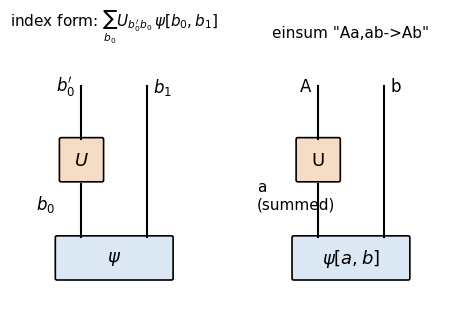

In [9]:
def tn_box(ax, x, y, w, h, label, color="#dbe7f3"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02", fc=color, ec="k", lw=1.2))
    ax.text(x, y, label, ha="center", va="center", fontsize=13)

def tn_leg(ax, x0, y0, x1, y1, label=None, side="right"):
    ax.plot([x0, x1], [y0, y1], "k", lw=1.5)
    if label:
        ax.text(x1 + (0.08 if side == "right" else -0.08), y1, label, ha="left" if side == "right" else "right",
                va="center", fontsize=12)

def tn_axes(ax, title):
    ax.set_xlim(-0.2, 2.2); ax.set_ylim(-0.2, 3.0); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 2, figsize=(5.6, 3.4))
ax = axes[0]; tn_axes(ax, r"index form: $\sum_{b_0}U_{b_0'b_0}\,\psi[b_0,b_1]$")
tn_box(ax, 1.0, 0.4, 1.4, 0.5, r"$\psi$")
tn_leg(ax, 0.6, 0.65, 0.6, 1.3); tn_leg(ax, 1.4, 0.65, 1.4, 2.5, r"$b_1$")
tn_box(ax, 0.6, 1.6, 0.5, 0.5, r"$U$", "#f6dcc5"); tn_leg(ax, 0.6, 1.85, 0.6, 2.5, r"$b_0'$", "left")
ax.text(0.05, 1.0, r"$b_0$", fontsize=12)
ax = axes[1]; tn_axes(ax, "einsum \"Aa,ab->Ab\"")
tn_box(ax, 1.0, 0.4, 1.4, 0.5, r"$\psi[a,b]$")
tn_leg(ax, 0.6, 0.65, 0.6, 1.3); tn_leg(ax, 1.4, 0.65, 1.4, 2.5, "b")
tn_box(ax, 0.6, 1.6, 0.5, 0.5, "U", "#f6dcc5"); tn_leg(ax, 0.6, 1.85, 0.6, 2.5, "A", "left")
ax.text(-0.15, 1.0, "a\n(summed)", fontsize=11)
save(fig, "fig_lab065_tn_one_qubit"); plt.show()


Both panels show the same diagram, the left one with the indices of equation (10) and the right one with the letters of the `einsum` string. The leg of qubit 0 runs from the state into the operator, so the index $b_0$, the letter `a`, is summed. The open legs $b_0'$ and $b_1$ are the indices of the new state. The code checks that the contraction gives the same vector as the Kronecker matrix.

Predict the four amplitudes of $(\hat I\otimes \hat Z)\,|0\rangle|+\rangle$ from the diagonal (9) before running the code, which prints them.

In [10]:
def apply_1q(psi, U, q):
    # contract the 2x2 matrix U with index q of the two-qubit state tensor
    t = psi.reshape(2, 2)
    out = jnp.einsum("Aa,ab->Ab", U, t) if q == 0 else jnp.einsum("Bb,ab->aB", U, t)
    return out.reshape(-1)

key, k1, k2 = jax.random.split(key, 3)
psi_r = jax.random.normal(k1, (4,)) + 1j * jax.random.normal(k2, (4,))
psi_r = psi_r / jnp.linalg.norm(psi_r)
for U in (Z, H, rotation([0, 1, 0], 0.7)):
    assert jnp.allclose(apply_1q(psi_r, U, 0), jnp.kron(U, I2) @ psi_r, atol=TOL)
    assert jnp.allclose(apply_1q(psi_r, U, 1), jnp.kron(I2, U) @ psi_r, atol=TOL)
print("U (x) I and I (x) U agree with the contraction on index 0 and index 1")
print("(I (x) Z)|0>|+> =", np.round(np.asarray(apply_1q(jnp.kron(ket0, plus), Z, 1)), 4), "= |0>|->")

U (x) I and I (x) U agree with the contraction on index 0 and index 1
(I (x) Z)|0>|+> = [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j] = |0>|->


## 7. Measuring both qubits

Measuring both qubits in the computational basis returns one of the four bit strings, and by the Born rule the bit string $b_0b_1$ appears with probability $p(b_0b_1)=|\psi[b_0,b_1]|^2$. A record of $M$ shots is a list of $M$ bit strings drawn from these four probabilities, which `sample_bitstrings` draws with one random key. The marginal of qubit 0, $p_0(b_0)=\sum_{b_1}p(b_0b_1)$, summarises what an observer who looks only at qubit 0 sees, and likewise for qubit 1. The single-qubit expectation values are $\langle \hat Z_q\rangle=p_q(0)-p_q(1)$. The correlator
$$\langle \hat Z_0\hat Z_1\rangle=\sum_{b_0b_1}(-1)^{b_0+b_1}p(b_0b_1) \tag{11}$$
is $+1$ when the two bits always agree and $-1$ when they always differ. A zero correlator means that agreement and disagreement are equally likely. Statistical independence is a stronger condition, the factorisation $p(b_0b_1)=p_0(b_0)\,p_1(b_1)$, and the distribution $(\tfrac12,\tfrac14,\tfrac14,0)$ has a zero correlator although its bits are dependent.

From shots each quantity is estimated by the mean of the $\pm1$ values, with the standard error $\mathrm{std}/\sqrt M$, where std is the sample standard deviation of the values.

In [11]:
def sample_bitstrings(key, psi, shots):
    # draw `shots` bit strings of two qubits from the Born probabilities; returns the bits of qubit 0 and qubit 1
    idx = np.asarray(jax.random.choice(key, 4, shape=(shots,), p=born_probabilities(psi)))
    return (idx >> 1) & 1, idx & 1          # qubit 0 is the most significant bit

def estimate(values):
    v = np.asarray(values, dtype=float)
    return v.mean(), v.std(ddof=1) / np.sqrt(len(v))

def z_statistics(psi):
    p = born_probabilities(psi).reshape(2, 2)
    p0, p1 = p.sum(axis=1), p.sum(axis=0)
    zz = jnp.sum(p * jnp.array([[1, -1], [-1, 1]]))
    return p, p0[0] - p0[1], p1[0] - p1[1], zz

psi_prod = jnp.kron(rotation([0, 1, 0], 2 * jnp.pi / 3) @ ket0, ket0)   # qubit 0 tilted, qubit 1 up
p, z0, z1, zz = z_statistics(psi_prod)
print("exact bit-string probabilities p(b0 b1):\n", np.round(np.asarray(p.real), 4))
print(f"exact <Z0> = {float(z0.real):.4f}, <Z1> = {float(z1.real):.4f}, <Z0 Z1> = {float(zz.real):.4f}")
SHOTS = 2000
key, k1 = jax.random.split(key)
b0, b1 = sample_bitstrings(k1, psi_prod, SHOTS)
m, e = estimate((-1.0) ** (b0 + b1))
print(f"{SHOTS} shots: <Z0 Z1> = {m:.3f} +- {e:.3f}")
assert abs(m - float(zz.real)) < 5 * e
NUMBERS["CorrShots"] = f"{SHOTS}"
NUMBERS["CorrTiltedEst"] = f"{m:.3f}"
NUMBERS["CorrTiltedSE"] = f"{e:.3f}"

exact bit-string probabilities p(b0 b1):
 [[0.25 0.  ]
 [0.75 0.  ]]
exact <Z0> = -0.5000, <Z1> = 1.0000, <Z0 Z1> = -0.5000
2000 shots: <Z0 Z1> = -0.489 +- 0.020


This second product state, with qubit 0 rotated by $2\pi/3$ about $y$ and qubit 1 in $|0\rangle$, gives random bits with unequal probabilities on qubit 0. Qubit 1 always reads $0$, so $\langle \hat Z_1\rangle=1$ and the correlator equals $\langle \hat Z_0\rangle=\cos(2\pi/3)=-0.5$. For a product state the joint probabilities factorise, $p(b_0b_1)=p_0(b_0)\,p_1(b_1)$, and every correlator is the product of single-qubit expectation values. The sampled correlator agrees with the exact value within its standard error.

## 8. Bit strings in different bases

A measurement along another axis rotates the qubit so that the chosen axis becomes the $z$ axis and then measures $\hat Z$. For the $\hat X$ basis the rotation is $\hat H$, and for the $\hat Y$ basis it is $\hat H\hat S^\dagger$. The outcome bit $0$ means the eigenvalue $+1$ of the measured Pauli operator. On the register each qubit can be measured in its own basis, so a measurement setting is a pair of letters such as $\hat X\hat X$ or $\hat Z\hat X$.

The same state produces different records in different settings. We take $|0\rangle\otimes|+\rangle$, qubit 0 up along $z$ and qubit 1 along $+x$. In the setting $\hat Z\hat Z$ qubit 0 always reads $0$ and qubit 1 is random. In $\hat Z\hat X$ both bits are fixed, and in $\hat X\hat X$ qubit 0 is random and qubit 1 is fixed.

In [12]:
def measure_in_setting(key, psi, setting, shots):
    # rotate each qubit so that its chosen axis becomes z, then sample bit strings
    phi = apply_1q(apply_1q(psi, BASIS_CHANGE[setting[0]], 0), BASIS_CHANGE[setting[1]], 1)
    return sample_bitstrings(key, phi, shots)

def counts(b0, b1):
    return {f"{x0}{x1}": int(np.sum((b0 == x0) & (b1 == x1))) for x0 in (0, 1) for x1 in (0, 1)}

assert jnp.allclose(BASIS_CHANGE["Y"] @ (ket0 + 1j * ket1) / jnp.sqrt(2.0), ket0, atol=TOL)   # |+i> -> |0>
psi_0plus = jnp.kron(ket0, plus)
SETTING_SHOTS = 1000
NUMBERS["SettingShots"] = f"{SETTING_SHOTS}"
for setting in ("ZZ", "ZX", "XX"):
    key, k1 = jax.random.split(key)
    b0, b1 = measure_in_setting(k1, psi_0plus, setting, SETTING_SHOTS)
    cnt = counts(b0, b1)
    print(f"|0>|+> measured in {setting}: counts {cnt}")
    for bits, word in (("00", "ZeroZero"), ("01", "ZeroOne"), ("10", "OneZero"), ("11", "OneOne")):
        NUMBERS[f"Count{setting}{word}"] = f"{cnt[bits]}"

|0>|+> measured in ZZ: counts {'00': 508, '01': 492, '10': 0, '11': 0}
|0>|+> measured in ZX: counts {'00': 1000, '01': 0, '10': 0, '11': 0}
|0>|+> measured in XX: counts {'00': 501, '01': 0, '10': 499, '11': 0}


Only the setting $\hat Z\hat X$, in which each qubit is measured along the axis of its own state, gives a deterministic record. In the other settings the random bits are equally likely, as the Born rule predicts for a state on the equator of the measured axis.

## 9. Two-qubit gates as evolution operators

Single-qubit gates act on each spin separately and, by the factor-by-factor action of Section 5, turn a product state into another product state. Correlations that no product state carries require an interaction between the spins, and a two-qubit gate is an interaction switched on for a time $t$. An Ising-type coupling, an energy proportional to the product of the same spin component of the two qubits, has the Hamiltonian $\hat{\mathcal H}_{\alpha\alpha}=\frac J2\,\hat\sigma_\alpha\otimes\hat\sigma_\alpha$ with $\alpha\in\{x,y,z\}$ and produces
$$\hat R_{\alpha\alpha}(\theta)=e^{-i\hat{\mathcal H}_{\alpha\alpha}t}=e^{-i\theta\,\hat\sigma_\alpha\otimes\hat\sigma_\alpha/2},\qquad\theta=Jt. \tag{12}$$
Since $(\hat\sigma_\alpha\otimes\hat\sigma_\alpha)^2=\hat I$, the identity $e^{-ia\hat P}=\cos a\,\hat I-i\sin a\,\hat P$ for $\hat P^2=\hat I$ gives
$$\hat R_{\alpha\alpha}(\theta)=\cos\tfrac\theta2\,\hat I-i\sin\tfrac\theta2\,\hat\sigma_\alpha\otimes\hat\sigma_\alpha . \tag{13}$$
Three fixed gates complete the set, and the first of them, the controlled NOT, is written with the projectors of Section 2 as
$$\widehat{\mathrm{CNOT}}=|0\rangle\langle0|\otimes \hat I+|1\rangle\langle1|\otimes \hat X, \tag{14}$$
which leaves qubit 1 unchanged when qubit 0 is $0$ and flips it when qubit 0 is $1$. Qubit 0 is the control and qubit 1 the target. On basis states CNOT maps $|b_0b_1\rangle$ to $|b_0,\,b_1\oplus b_0\rangle$, where $\oplus$ is addition modulo 2, so CNOT is the reversible version of the classical XOR gate.

| $b_0b_1$ in | 00 | 01 | 10 | 11 |
|---|---|---|---|---|
| $b_0,\,b_1\oplus b_0$ out | 00 | 01 | 11 | 10 |

The truth table keeps the control bit, so the input can always be recovered from the output. The ordinary XOR has a single output bit and loses the input. In a circuit diagram each qubit is a horizontal line, a wire, with qubit 0 on top and time running from left to right. CNOT is drawn as a dot on the control wire joined by a vertical line to the symbol $\oplus$ on the target wire. The controlled $\hat Z$ gate $\widehat{\mathrm{CZ}}=|0\rangle\langle0|\otimes \hat I+|1\rangle\langle1|\otimes \hat Z=\mathrm{diag}(1,1,1,-1)$ multiplies $|11\rangle$ by $-1$, and the SWAP gate exchanges the states of the two qubits, $|01\rangle\leftrightarrow|10\rangle$,
$$\widehat{\mathrm{SWAP}}=\begin{pmatrix}1&0&0&0\\0&0&1&0\\0&1&0&0\\0&0&0&1\end{pmatrix}. \tag{15}$$
In the tensor language a $4\times4$ gate is reshaped into a tensor $G[b_0',b_1',b_0,b_1]$ with two output and two input legs. Its action is the contraction `"ABab,ab->AB"`, drawn as a box joined to both legs of the state.

CNOT in the basis 00, 01, 10, 11:
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 0 1]
 [0 0 1 0]]
closed-form rotations = matrix exponentials; gate contraction = matrix product


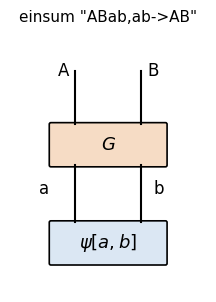

In [13]:
PAULI = {"x": X, "y": Y, "z": Z}

def R2(alpha, theta):
    P = jnp.kron(PAULI[alpha], PAULI[alpha])
    return jnp.cos(theta / 2) * jnp.eye(4, dtype=CDTYPE) - 1j * jnp.sin(theta / 2) * P

CNOT = jnp.kron(P0, I2) + jnp.kron(P1, X)
CZ = jnp.kron(P0, I2) + jnp.kron(P1, Z)
SWAP = jnp.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], dtype=CDTYPE)

def apply_2q(psi, G):
    # contract the (2,2,2,2) gate tensor with both indices of the state tensor
    return jnp.einsum("ABab,ab->AB", G.reshape(2, 2, 2, 2), psi.reshape(2, 2)).reshape(-1)

for alpha in "xyz":
    for th in (0.3, jnp.pi / 2, 2.0):
        assert jnp.allclose(R2(alpha, th), expm(-1j * th * jnp.kron(PAULI[alpha], PAULI[alpha]) / 2), atol=1e-10)
for G in (CNOT, CZ, SWAP, R2("x", 0.4)):
    assert jnp.allclose(apply_2q(psi_r, G), G @ psi_r, atol=TOL)
assert jnp.allclose(CZ, jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE)), atol=TOL)
assert jnp.allclose(SWAP @ jnp.kron(plus, ket1), jnp.kron(ket1, plus), atol=TOL)
print("CNOT in the basis 00, 01, 10, 11:\n", np.asarray(CNOT.real).astype(int))

fig, ax = plt.subplots(figsize=(3.0, 3.4)); tn_axes(ax, "einsum \"ABab,ab->AB\"")
tn_box(ax, 1.0, 0.4, 1.4, 0.5, r"$\psi[a,b]$")
tn_leg(ax, 0.6, 0.65, 0.6, 1.35); tn_leg(ax, 1.4, 0.65, 1.4, 1.35)
tn_box(ax, 1.0, 1.6, 1.4, 0.5, r"$G$", "#f6dcc5")
tn_leg(ax, 0.6, 1.85, 0.6, 2.5, "A", "left"); tn_leg(ax, 1.4, 1.85, 1.4, 2.5, "B")
ax.text(0.15, 1.0, "a", fontsize=12); ax.text(1.55, 1.0, "b", fontsize=12)
save(fig, "fig_lab065_tn_two_qubit"); plt.show()
print("closed-form rotations = matrix exponentials; gate contraction = matrix product")

The gate box takes both legs of the state as inputs, the summed indices `a` and `b`, and returns two new legs `A` and `B`.

### 9.1 The rotation picture of each two-qubit gate

Each two-qubit gate is again a rotation or an evolution operator. The gate $\hat R_{xx}(\theta)$ couples $|00\rangle$ only with $|11\rangle$ and $|01\rangle$ only with $|10\rangle$. Restricted to the pair $\{|00\rangle,|11\rangle\}$ it is the matrix of an ordinary $\hat R_x(\theta)$, a rotation of a Bloch sphere with north pole $|00\rangle$ and south pole $|11\rangle$. At $\theta=\pi/2$ it takes $|00\rangle$ to the equator of that sphere, $(|00\rangle-i|11\rangle)/\sqrt2$.

The gate $\hat R_{zz}(\theta)$ is diagonal. Since $\hat Z\otimes \hat Z=|0\rangle\langle0|\otimes \hat Z-|1\rangle\langle1|\otimes \hat Z$, it rotates qubit 1 about $z$ by $+\theta$ when qubit 0 is $|0\rangle$ and by $-\theta$ when qubit 0 is $|1\rangle$. The gate is thus a rotation of one qubit conditioned on the other.

CNOT is a conditional rotation by $\pi$ about $x$. Since $\hat X=i\hat R_x(\pi)$, the conditional rotation $|0\rangle\langle0|\otimes \hat I+|1\rangle\langle1|\otimes \hat R_x(\pi)$ equals CNOT up to the phase $-i$ on the branch in which qubit 0 is $1$. The phase gate $\hat S$ on qubit 0 supplies the factor $i$. CNOT is also the evolution operator
$$\widehat{\mathrm{CNOT}}=\exp\big[\mp i\pi(\hat I-\hat Z)\otimes(\hat I-\hat X)/4\big], \tag{16}$$
generated by $\hat P=\frac{\hat I-\hat Z}2\otimes\frac{\hat I-\hat X}2$, the product of the projector on $|1\rangle$ of qubit 0 and the projector on $|-\rangle$ of qubit 1. For a projector $e^{\mp i\pi \hat P}=\hat I-2\hat P$ with either sign, and $\hat I-2\hat P$ flips the sign of $|1\rangle|-\rangle$ alone, which is the action of CNOT. CZ is the conditional rotation by $\pi$ about $z$, $\widehat{\mathrm{CZ}}=(\hat S\otimes \hat I)\,[\,|0\rangle\langle0|\otimes \hat I+|1\rangle\langle1|\otimes \hat R_z(\pi)]$, and the evolution operator $\widehat{\mathrm{CZ}}=\exp[-i\pi(\hat I-\hat Z)\otimes(\hat I-\hat Z)/4]$ generated by the projector on $|11\rangle$.

SWAP is generated by the Heisenberg exchange coupling $\hat X\otimes \hat X+\hat Y\otimes \hat Y+\hat Z\otimes \hat Z=4\,\hat{\mathbf S}_0\cdot\hat{\mathbf S}_1$, with the spin operators $\hat{\mathbf S}_q=\hat{\boldsymbol\sigma}_q/2$. Its eigenstates with the eigenvalue $+1$ are the three symmetric states $|00\rangle$, $|11\rangle$ and $(|01\rangle+|10\rangle)/\sqrt2$, which are unchanged by an exchange of the qubits. The antisymmetric singlet $(|01\rangle-|10\rangle)/\sqrt2$ has the eigenvalue $-3$. Hence
$$\widehat{\mathrm{SWAP}}=\tfrac12(\hat I+\hat X\otimes \hat X+\hat Y\otimes \hat Y+\hat Z\otimes \hat Z)=e^{i\pi/4}\exp\big[-i\pi(\hat X\otimes \hat X+\hat Y\otimes \hat Y+\hat Z\otimes \hat Z)/4\big], \tag{17}$$
which leaves the symmetric states unchanged and multiplies the singlet by $-1$. The code checks each statement.

In [14]:
th = 0.9
sub = R2("x", th)[jnp.ix_(jnp.array([0, 3]), jnp.array([0, 3]))]
assert jnp.allclose(sub, rotation([1, 0, 0], th), atol=TOL)                     # R_xx = R_x in {|00>,|11>}
sub2 = R2("x", th)[jnp.ix_(jnp.array([1, 2]), jnp.array([1, 2]))]
assert jnp.allclose(sub2, rotation([1, 0, 0], th), atol=TOL)                    # and in {|01>,|10>}
Rz = lambda t: rotation([0, 0, 1], t)
assert jnp.allclose(R2("z", th), jnp.kron(P0, Rz(th)) + jnp.kron(P1, Rz(-th)), atol=TOL)
CRx = jnp.kron(P0, I2) + jnp.kron(P1, rotation([1, 0, 0], jnp.pi))
assert jnp.allclose(jnp.kron(S, I2) @ CRx, CNOT, atol=TOL)
assert jnp.allclose(expm(-1j * jnp.pi / 4 * jnp.kron(I2 - Z, I2 - X)), CNOT, atol=1e-10)
assert jnp.allclose(expm(+1j * jnp.pi / 4 * jnp.kron(I2 - Z, I2 - X)), CNOT, atol=1e-10)   # both signs
CRz = jnp.kron(P0, I2) + jnp.kron(P1, Rz(jnp.pi))
assert jnp.allclose(jnp.kron(S, I2) @ CRz, CZ, atol=TOL)
assert jnp.allclose(expm(-1j * jnp.pi / 4 * jnp.kron(I2 - Z, I2 - Z)), CZ, atol=1e-10)
heis = jnp.kron(X, X) + jnp.kron(Y, Y) + jnp.kron(Z, Z)
assert jnp.allclose(SWAP, (jnp.eye(4) + heis) / 2, atol=TOL)
assert jnp.allclose(SWAP, jnp.exp(1j * jnp.pi / 4) * expm(-1j * jnp.pi / 4 * heis), atol=1e-10)
singlet = (basis_vector([0, 1]) - basis_vector([1, 0])) / jnp.sqrt(2.0)
assert jnp.allclose(heis @ singlet, -3 * singlet, atol=TOL)
half = R2("x", jnp.pi / 2) @ jnp.kron(ket0, ket0)
print("eigenvalues of XX+YY+ZZ:", np.round(np.linalg.eigvalsh(np.asarray(heis)), 6))
print("R_xx(pi/2)|00> =", np.round(np.asarray(half), 4))
print("every rotation and evolution picture holds")

eigenvalues of XX+YY+ZZ: [-3.  1.  1.  1.]
R_xx(pi/2)|00> = [0.7071+0.j     0.    +0.j     0.    +0.j     0.    -0.7071j]
every rotation and evolution picture holds


### 9.2 Each two-qubit gate as a matrix, an action and a generator

The matrix of each two-qubit gate in the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ is given by equations (13) to (17). The code prints it together with the action on the four basis states, checked as a truth table. The last column gives the generator of each gate, with the angle set by the coupling and the time it is switched on, or its construction from other gates.

| gate | action on basis states | generator or construction |
|---|---|---|
| $\hat R_{zz}(\theta)$ | phase $e^{-i\theta/2}$ on $|00\rangle,|11\rangle$ and $e^{i\theta/2}$ on $|01\rangle,|10\rangle$ | Ising coupling $\frac J2\hat Z\otimes\hat Z$ switched on for $t=\theta/J$ |
| $\hat R_{xx}(\theta)$ | rotates $|00\rangle$ towards $-i|11\rangle$ and $|01\rangle$ towards $-i|10\rangle$ | coupling $\frac J2\hat X\otimes\hat X$ switched on for $t=\theta/J$ |
| $\widehat{\mathrm{CZ}}$ | sign $-1$ on $|11\rangle$ | $\hat R_{zz}(\pi/2)$ followed by rotations $\hat R_z(-\pi/2)$ of both qubits |
| $\widehat{\mathrm{CNOT}}$ | $|b_0b_1\rangle\to|b_0,b_1\oplus b_0\rangle$ | $\widehat{\mathrm{CZ}}$ between Hadamard gates on the target, $(\hat I\otimes\hat H)\,\widehat{\mathrm{CZ}}\,(\hat I\otimes\hat H)$ |
| $\widehat{\mathrm{SWAP}}$ | $|01\rangle\leftrightarrow|10\rangle$, $|00\rangle$ and $|11\rangle$ unchanged | exchange coupling $J_{\rm ex}\hat{\mathbf S}_0\cdot\hat{\mathbf S}_1=\frac{J_{\rm ex}}4(\hat X\hat X+\hat Y\hat Y+\hat Z\hat Z)$ switched on for $J_{\rm ex}t=\pi$ |

These couplings are realised in specific devices, which are described in Lab 068 and in Part II of the lecture notes. The code also checks the construction of CZ and CNOT from the Ising rotation and the exchange time of SWAP.

In [15]:
# each two-qubit gate: matrix, truth table on |00>,|01>,|10>,|11>, and its generator or construction
labels = ["00", "01", "10", "11"]
def truth_table(G):
    rows = []
    for k, lab in enumerate(labels):
        out = np.asarray(G[:, k])
        terms = [f"{complex(np.round(a, 3))}|{labels[j]}>" for j, a in enumerate(out) if abs(a) > 1e-9]
        rows.append(f"|{lab}> -> " + " + ".join(terms))
    return rows
gates2 = {"R_zz(pi/2)": R2("z", jnp.pi / 2), "R_xx(pi/2)": R2("x", jnp.pi / 2), "CZ": CZ, "CNOT": CNOT, "SWAP": SWAP}
for name, G in gates2.items():
    print(name, "matrix:\n", np.round(np.asarray(G), 3))
    print("   " + "\n   ".join(truth_table(G)))
# truth tables as asserts
for b0 in (0, 1):
    for b1 in (0, 1):
        assert jnp.allclose(CNOT @ basis_vector([b0, b1]), basis_vector([b0, b1 ^ b0]), atol=TOL)
        assert jnp.allclose(SWAP @ basis_vector([b0, b1]), basis_vector([b1, b0]), atol=TOL)
        assert jnp.allclose(CZ @ basis_vector([b0, b1]), (-1) ** (b0 * b1) * basis_vector([b0, b1]), atol=TOL)
# generators and constructions, up to a global phase
J_c, Rz1 = 1.0, (lambda t: rotation([0, 0, 1], t))
U_ising = expm(-1j * (jnp.pi / (2 * J_c)) * (J_c / 2) * jnp.kron(Z, Z))           # Ising coupling on for t = (pi/2)/J
cz_phys = jnp.exp(-1j * jnp.pi / 4) * jnp.kron(Rz1(-jnp.pi / 2), Rz1(-jnp.pi / 2)) @ U_ising
assert jnp.allclose(cz_phys, CZ, atol=1e-10)
assert jnp.allclose(jnp.kron(I2, H) @ CZ @ jnp.kron(I2, H), CNOT, atol=TOL)
heis4 = (jnp.kron(X, X) + jnp.kron(Y, Y) + jnp.kron(Z, Z)) / 4
U_exch = expm(-1j * jnp.pi * heis4)                                                 # exchange (J_ex/4)(XX+YY+ZZ), J_ex t = pi
assert jnp.allclose(jnp.exp(1j * jnp.pi / 4) * U_exch, SWAP, atol=1e-10)
assert jnp.allclose(expm(-1j * 0.7 * (J_c / 2) * jnp.kron(X, X)), R2("x", 0.7 * J_c), atol=1e-10)
print("truth tables and the constructions of CZ, CNOT, SWAP and R_xx hold")

R_zz(pi/2) matrix:
 [[0.707-0.707j 0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j 0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.707+0.707j 0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.707-0.707j]]
   |00> -> (0.707-0.707j)|00>
   |01> -> (0.707+0.707j)|01>
   |10> -> (0.707+0.707j)|10>
   |11> -> (0.707-0.707j)|11>
R_xx(pi/2) matrix:
 [[0.707+0.j    0.   +0.j    0.   +0.j    0.   -0.707j]
 [0.   +0.j    0.707+0.j    0.   -0.707j 0.   +0.j   ]
 [0.   +0.j    0.   -0.707j 0.707+0.j    0.   +0.j   ]
 [0.   -0.707j 0.   +0.j    0.   +0.j    0.707+0.j   ]]
   |00> -> (0.707+0j)|00> + -0.707j|11>
   |01> -> (0.707+0j)|01> + -0.707j|10>
   |10> -> -0.707j|01> + (0.707+0j)|10>
   |11> -> -0.707j|00> + (0.707+0j)|11>
CZ matrix:
 [[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]]
   |00> -> (1+0j)|00>
   |01> -> (1+0j)|01>
   |10> -> (1+0j)|10>
   |11> -> (-1+0j)|

## 10. Expectation values as contractions

The expectation value of an observable $\hat O$ on the register is
$$\langle\psi|\hat O|\psi\rangle=\sum\psi^*[a',b']\,O[a',b',a,b]\,\psi[a,b]. \tag{18}$$
As a diagram it is a closed network of three boxes, $\psi^*$ on top, the operator in the middle and $\psi$ below. All legs are joined, so the result is a number. The `einsum` string is `"AB,ABab,ab->"`. For an operator on one qubit the box of the other qubit is a plain line, the identity.

network psi* - O - psi equals <psi|O|psi> computed with matrices


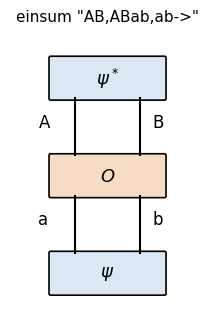

In [16]:
def expect(psi, O):
    t = psi.reshape(2, 2)
    return jnp.einsum("AB,ABab,ab->", t.conj(), O.reshape(2, 2, 2, 2), t)

for O in (jnp.kron(Z, Z), jnp.kron(X, I2), jnp.kron(Y, X)):
    assert jnp.allclose(expect(psi_r, O), jnp.vdot(psi_r, O @ psi_r), atol=TOL)
assert jnp.allclose(expect(psi_prod, jnp.kron(Z, Z)), zz, atol=TOL)

fig, ax = plt.subplots(figsize=(3.0, 3.8)); tn_axes(ax, "einsum \"AB,ABab,ab->\""); ax.set_ylim(-0.2, 3.4)
tn_box(ax, 1.0, 0.4, 1.4, 0.5, r"$\psi$")
tn_box(ax, 1.0, 1.6, 1.4, 0.5, r"$O$", "#f6dcc5")
tn_box(ax, 1.0, 2.8, 1.4, 0.5, r"$\psi^*$")
for x in (0.6, 1.4):
    tn_leg(ax, x, 0.65, x, 1.35); tn_leg(ax, x, 1.85, x, 2.55)
ax.text(0.15, 1.0, "a", fontsize=12); ax.text(1.55, 1.0, "b", fontsize=12)
ax.text(0.15, 2.2, "A", fontsize=12); ax.text(1.55, 2.2, "B", fontsize=12)
save(fig, "fig_lab065_tn_expectation"); plt.show()
print("network psi* - O - psi equals <psi|O|psi> computed with matrices")

Every index is summed, and the network evaluates to the expectation value.

## 11. Pauli strings and gates on $N$ qubits

On a register of $N$ qubits the observables become Pauli strings, and a gate on one qubit becomes a gate on qubit $q$ of $N$. A two-qubit gate may act on any pair $(i,j)$, also on distant qubits. Each object is first built as a Kronecker product of operators, as in Section 5, and then as the equivalent contraction of the state tensor, the efficient form.

### 11.1 Pauli strings

A Pauli string on $N$ qubits is a Kronecker product of one single-qubit operator per qubit,
$$\hat P=\hat P_0\otimes \hat P_1\otimes\dots\otimes \hat P_{N-1},\qquad \hat P_q\in\{\hat I,\hat X,\hat Y,\hat Z\}, \tag{19}$$
with qubit 0 as the leftmost factor. We label it by its letters, for example `XIZI`. In formulas we keep only the non-identity factors with their qubit as subscript, $\hat X_0\hat Z_2\equiv \hat X\otimes \hat I\otimes \hat Z\otimes \hat I$ for $N=4$. There are $4^N$ Pauli strings. Each is Hermitian and squares to the identity, because every factor does, so its eigenvalues are $\pm1$.

Two Pauli strings either commute or anticommute. The factors anticommute on every qubit where the two strings carry different non-identity letters and commute on all other qubits. The strings anticommute when the number of such qubits is odd and commute when it is even. For example $\hat X_0\hat X_1$ and $\hat Z_0\hat Z_1$ differ on two qubits and commute, whereas $\hat X_0$ and $\hat Z_0\hat Z_1$ differ on one qubit and anticommute.

The $4^N$ Pauli strings form a basis of all $2^N\times2^N$ matrices, orthogonal in the sense $\mathrm{Tr}(\hat P\hat P')=2^N\delta_{PP'}$. Every Hamiltonian of $N$ qubits is therefore a real linear combination of Pauli strings with the coefficients $c_P=\mathrm{Tr}(\hat P\,\hat{\mathcal H})/2^N$. The Heisenberg exchange of two spins in a field, $\hat{\mathcal H}=J(\hat X_0\hat X_1+\hat Y_0\hat Y_1+\hat Z_0\hat Z_1)+h(\hat Z_0+\hat Z_1)$, is an example with five nonzero coefficients out of sixteen. Strings made only of $\hat I$ and $\hat Z$ are diagonal in the computational basis. On the bit string $b_0\dots b_{N-1}$ the string $\hat Z_i\hat Z_j\cdots$ takes the value $(-1)^{b_i+b_j+\dots}$, the parity of the selected bits. The code fixes how such operators are stored, builds any string from its label with `kron` and checks these properties.

Most entries of a Kronecker product with identities are zero. The operator $\hat G_q=\hat I\otimes\dots\otimes \hat G\otimes\dots\otimes \hat I$ of a one-qubit gate on $N$ qubits has $4^N$ entries, yet each of its rows contains at most two nonzero entries, those of one row of $\hat G$. The operator thus holds at most $2\cdot2^N$ nonzero entries, and a two-qubit gate on $(i,j)$ at most $4\cdot2^N$. A sparse matrix stores only the nonzero entries with their positions. In the compressed sparse row (CSR) format of `scipy.sparse`, each nonzero entry takes about 20 bytes, for the complex value and its column index, plus 4 bytes per row. A matrix–vector product costs about `nnz` multiplications, compared with $4^N$ for a dense matrix.

We therefore build the operators on $N$ qubits with `scipy.sparse`, while the one- and two-qubit examples stay dense. The $2\times2$ building blocks become `sp.csr_matrix`, and the identity is `sp.identity(2)`. The helper `op_on_qubits` folds `sp.kron(..., format="csr")` over the list of factors, with the operator `ops[q]` on qubit $q$ and the identity on every other qubit. Dense arrays, `.toarray()`, serve only to display small matrices and to check the sparse results against the dense Kronecker products and the `einsum` contractions. The code compares the storage for $N=4$, $10$ and $16$.

In [17]:
import scipy.sparse as sp
from functools import reduce

def csr(G):
    # a small dense matrix as a sparse CSR matrix
    return sp.csr_matrix(np.asarray(G))

def op_on_qubits(ops, N):
    # Kronecker product over N qubits: ops[q] on qubit q (a dict), the identity elsewhere, qubit 0 leftmost
    factors = [csr(ops[q]) if q in ops else sp.identity(2, dtype=complex, format="csr") for q in range(N)]
    return reduce(lambda A, B: sp.kron(A, B, format="csr"), factors)

assert np.allclose(op_on_qubits({0: Z}, 2).toarray(), np.asarray(jnp.kron(Z, I2)))       # Z_0 of Section 5
print(f"{'N':>3s} {'4^N entries':>16s} {'nnz of H_0':>12s} {'dense memory':>14s} {'sparse memory':>14s}")
for N_ in (4, 10, 16):
    G_sp = op_on_qubits({0: H}, N_)
    assert G_sp.nnz == 2 * 2 ** N_                                          # two nonzeros per row
    dense_bytes = 16 * 4 ** N_
    sparse_bytes = G_sp.data.nbytes + G_sp.indices.nbytes + G_sp.indptr.nbytes
    print(f"{N_:3d} {4 ** N_:16,d} {G_sp.nnz:12,d} {dense_bytes / 2**20:11.3g} MiB {sparse_bytes / 2**20:11.3g} MiB")


  N      4^N entries   nnz of H_0   dense memory  sparse memory
  4              256           32     0.00391 MiB    0.000675 MiB
 10        1,048,576        2,048          16 MiB       0.043 MiB
 16    4,294,967,296      131,072    6.55e+04 MiB        2.75 MiB


In [18]:
from functools import reduce
from itertools import product
PAULI1 = {"I": I2, "X": X, "Y": Y, "Z": Z}

def pauli_string(label):
    # Kronecker product of the single-qubit factors, qubit 0 = first letter = leftmost factor
    return reduce(jnp.kron, [PAULI1[c] for c in label])

def anticommute(l1, l2):
    # odd number of positions with two different non-identity letters
    return sum(a != "I" and b != "I" and a != b for a, b in zip(l1, l2)) % 2 == 1

P = pauli_string("XIZI")
assert jnp.allclose(P, jnp.kron(jnp.kron(jnp.kron(X, I2), Z), I2), atol=TOL)            # X_0 Z_2 for N = 4
labels3 = ["".join(t) for t in product("IXYZ", repeat=3)]
strings3 = {l: np.asarray(pauli_string(l)) for l in labels3}
assert len(labels3) == 4 ** 3
for l1 in labels3:
    A = strings3[l1]
    assert np.allclose(A, A.conj().T) and np.allclose(A @ A, np.eye(8))                    # Hermitian, squares to I
    for l2 in labels3:
        B = strings3[l2]
        sign = -1 if anticommute(l1, l2) else 1
        assert np.allclose(A @ B, sign * B @ A)                                             # commute or anticommute
        assert abs(np.trace(A @ B) - (8 if l1 == l2 else 0)) < 1e-12                        # Tr(P P') = 2^N delta
print("all 64 Pauli strings of 3 qubits: Hermitian, square to I, pairwise commute or anticommute, orthogonal")

# the register Hamiltonian as a sum of Pauli strings, coefficients c_P = Tr(P H) / 2^N
Jc, hc = 1.0, 0.5
H_reg = Jc * (pauli_string("XX") + pauli_string("YY") + pauli_string("ZZ")) + hc * (pauli_string("ZI") + pauli_string("IZ"))
coeffs = {"".join(t): float(jnp.real(jnp.trace(pauli_string("".join(t)) @ H_reg)) / 4) for t in product("IXYZ", repeat=2)}
print("nonzero Pauli coefficients of H:", {l: c for l, c in coeffs.items() if abs(c) > 1e-12})
assert jnp.allclose(sum(c * pauli_string(l) for l, c in coeffs.items()), H_reg, atol=TOL)

# Z strings are diagonal with the parity of the selected bits
D = np.real(np.diag(np.asarray(pauli_string("ZIZI"))))
for i in range(16):
    bits = [(i >> (3 - q)) & 1 for q in range(4)]
    assert D[i] == (-1) ** (bits[0] + bits[2])
print("diagonal of Z_0 Z_2 (N = 4):", D.astype(int), "= (-1)^(b_0 + b_2)")

# the same Pauli strings as sparse matrices
def pauli_string_sparse(label):
    return op_on_qubits({q: PAULI1[c] for q, c in enumerate(label) if c != "I"}, len(label))
for l in labels3:
    assert np.allclose(pauli_string_sparse(l).toarray(), strings3[l])
P_sp = pauli_string_sparse("XIZI")
print(f"X_0 Z_2 as a sparse matrix: nnz = {P_sp.nnz} of {4 ** 4} entries (one nonzero per row)")


all 64 Pauli strings of 3 qubits: Hermitian, square to I, pairwise commute or anticommute, orthogonal
nonzero Pauli coefficients of H: {'IZ': 0.5, 'XX': 1.0, 'YY': 1.0, 'ZI': 0.5, 'ZZ': 1.0}
diagonal of Z_0 Z_2 (N = 4): [ 1  1 -1 -1  1  1 -1 -1 -1 -1  1  1 -1 -1  1  1] = (-1)^(b_0 + b_2)
X_0 Z_2 as a sparse matrix: nnz = 16 of 256 entries (one nonzero per row)


### 11.2 A one-qubit gate on qubit $q$ of $N$

A gate $\hat G$ that acts on qubit $q$ alone is the Kronecker product with $\hat G$ in position $q$ and identities everywhere else,
$$\hat G_q=\hat I\otimes\dots\otimes \hat I\otimes\underbrace{\hat G}_{\text{qubit }q}\otimes \hat I\otimes\dots\otimes \hat I . \tag{20}$$
For the Hadamard gate on qubit 2 of $N=4$ qubits this is $\hat H_2=\hat I\otimes \hat I\otimes \hat H\otimes \hat I$, a $16\times16$ matrix. Read from the left with the block form (8), $\hat I\otimes \hat I\otimes(\hat H\otimes \hat I)$ is block diagonal with four copies of the $4\times4$ matrix $\hat H\otimes \hat I$. In turn, $\hat H\otimes \hat I=\frac1{\sqrt2}\begin{pmatrix}I&I\\I&-I\end{pmatrix}$ is made of $2\times2$ identity blocks. On the amplitudes the gate mixes pairs of bit strings that differ only in bit $q$. For $q=2$ of $N=4$ these are the indices $i$ and $i+2^{N-1-q}=i+2$ with $b_2=0$, for example $0000$ and $0010$. Each pair is transformed by the matrix of $\hat H$,
$$\psi'_{b_0b_1\,0\,b_3}=\tfrac1{\sqrt2}\big(\psi_{b_0b_1\,0\,b_3}+\psi_{b_0b_1\,1\,b_3}\big),\qquad \psi'_{b_0b_1\,1\,b_3}=\tfrac1{\sqrt2}\big(\psi_{b_0b_1\,0\,b_3}-\psi_{b_0b_1\,1\,b_3}\big). \tag{21}$$
The partner of index $i$ is $i\oplus2^{N-1-q}$, the index with bit $q$ flipped.

Two cheaper implementations of the same action never build the $2^N\times2^N$ matrix. The first contracts $\hat G$ with axis $q$ of the state tensor, the $N$-qubit version of equation (10). With `jnp.tensordot` the matrix is contracted with axis $q$, and `jnp.moveaxis` returns the new axis to position $q$. In `einsum` notation for $N=4$ and $q=2$ the string is `"Cc,abcd->abCd"`. The second reshapes the flat vector to the shape $(2^q,\,2,\,2^{N-q-1})$, which groups the qubits before $q$, qubit $q$ and the qubits after it. The gate $\hat G$ then acts on the middle axis.

The Kronecker matrix has $4^N$ entries, whereas the contraction needs about $4\cdot2^N$ multiplications, so only the contraction scales to many qubits. The code builds $\hat H_2$ with `kron`, using a helper `op_on_qubit` that folds `kron` over the list $[\hat I,\dots,\hat G,\dots,\hat I]$, and checks the three implementations against each other.

In [19]:
def op_on_qubit(G, q, N):
    # Kronecker product of the list [I, ..., G (position q), ..., I], qubit 0 leftmost
    return reduce(jnp.kron, [G if k == q else I2 for k in range(N)])

def apply_1q_tensordot(psi, G, q, N):
    t = jnp.tensordot(G, psi.reshape((2,) * N), axes=([1], [q]))      # new axis comes first
    return jnp.moveaxis(t, 0, q).reshape(-1)

def apply_1q_reshape(psi, G, q, N):
    t = psi.reshape(2 ** q, 2, 2 ** (N - q - 1))
    return jnp.einsum("ij,ajb->aib", G, t).reshape(-1)

N4 = 4
H_2 = jnp.kron(jnp.kron(jnp.kron(I2, I2), H), I2)                  # I (x) I (x) H (x) I, written out
assert jnp.allclose(H_2, op_on_qubit(H, 2, N4), atol=TOL)
k1, k2 = jax.random.split(jax.random.PRNGKey(6511))     # own key; the recorded experiments use key 65
psi4 = jax.random.normal(k1, (16,)) + 1j * jax.random.normal(k2, (16,)); psi4 = psi4 / jnp.linalg.norm(psi4)
out_kron = H_2 @ psi4
assert jnp.allclose(out_kron, apply_1q_tensordot(psi4, H, 2, N4), atol=TOL)
assert jnp.allclose(out_kron, apply_1q_reshape(psi4, H, 2, N4), atol=TOL)
assert jnp.allclose(out_kron, jnp.einsum("Cc,abcd->abCd", H, psi4.reshape(2, 2, 2, 2)).reshape(-1), atol=TOL)
for q in range(N4):                                                 # every qubit, a random rotation
    G = rotation([0.3, -0.5, 0.8], 1.2)
    assert jnp.allclose(op_on_qubit(G, q, N4) @ psi4, apply_1q_tensordot(psi4, G, q, N4), atol=TOL)
    assert jnp.allclose(op_on_qubit(G, q, N4) @ psi4, apply_1q_reshape(psi4, G, q, N4), atol=TOL)
# the pairs mixed by H_2: index i with bit 2 equal to 0, and its partner i XOR 2^(N-1-q)
pairs = [(i, i ^ 2 ** (N4 - 1 - 2)) for i in range(16) if not (i >> 1) & 1]
for i, j in pairs:
    assert jnp.allclose(out_kron[i], (psi4[i] + psi4[j]) / jnp.sqrt(2.0), atol=TOL)
    assert jnp.allclose(out_kron[j], (psi4[i] - psi4[j]) / jnp.sqrt(2.0), atol=TOL)
print("pairs mixed by H_2:", [(format(i, "04b"), format(j, "04b")) for i, j in pairs])
print("kron matrix, tensordot on axis q and the reshape trick agree for every qubit q")

H_2_sp = op_on_qubits({2: H}, N4)                                   # sparse I (x) I (x) H (x) I
assert np.allclose(H_2_sp.toarray(), np.asarray(H_2)) and np.allclose(H_2_sp @ np.asarray(psi4), np.asarray(out_kron))
print(f"sparse H_2: nnz = {H_2_sp.nnz} = 2 * 2^N of {4 ** N4} entries; sparse product = dense product")


pairs mixed by H_2: [('0000', '0010'), ('0001', '0011'), ('0100', '0110'), ('0101', '0111'), ('1000', '1010'), ('1001', '1011'), ('1100', '1110'), ('1101', '1111')]
kron matrix, tensordot on axis q and the reshape trick agree for every qubit q
sparse H_2: nnz = 32 = 2 * 2^N of 256 entries; sparse product = dense product


### 11.3 A two-qubit gate on a pair $(i,j)$

A two-qubit gate on the pair $(i,j)$ is again a Kronecker product, now with identities on all qubits except $i$ and $j$. For CNOT with control $i$ and target $j$ the projector form (14) gives
$$\widehat{\mathrm{CNOT}}_{i\to j}=\big(|0\rangle\langle0|\big)_i\otimes \hat I_{\rm rest}+\big(|1\rangle\langle1|\big)_i\otimes \hat X_j\otimes \hat I_{\rm rest}, \tag{22}$$
where each term is a Kronecker product over all $N$ qubits, with $|0\rangle\langle0|$ or $|1\rangle\langle1|$ at position $i$, $\hat X$ or $\hat I$ at position $j$, and $\hat I$ elsewhere. The qubits need not be neighbours, and the control may stand below the target. On basis states the gate is a permutation of bit strings, which flips $b_j$ when $b_i=1$ and leaves all other bit strings unchanged. For $N=4$, $\widehat{\mathrm{CNOT}}_{0\to3}$ exchanges $1000\leftrightarrow1001$, $1010\leftrightarrow1011$, $1100\leftrightarrow1101$ and $1110\leftrightarrow1111$. The gate $\widehat{\mathrm{CNOT}}_{3\to0}$ exchanges $0001\leftrightarrow1001$, $0011\leftrightarrow1011$, $0101\leftrightarrow1101$ and $0111\leftrightarrow1111$.

The projector form with `kron`, the contraction of the $(2,2,2,2)$ gate tensor $G[b_i',b_j',b_i,b_j]$ with axes $i$ and $j$ of the state tensor and the permutation of indices must agree. For $\widehat{\mathrm{CNOT}}_{0\to3}$ and $N=4$ the contraction string is `"ADad,abcd->AbcD"`, in which the legs of qubits 1 and 2 pass through untouched. The contraction works for any $4\times4$ gate, and we also check $\hat R_{zz}$ and CZ on the pair $(1,3)$. When a device couples only some pairs of qubits, a gate on an uncoupled pair is compiled with SWAP gates that bring the two qubits together.

With these gates the GHZ state $(|0000\rangle+|1111\rangle)/\sqrt2$ is prepared by $\hat H_0$ followed by the chain $\widehat{\mathrm{CNOT}}_{0\to1}$, $\widehat{\mathrm{CNOT}}_{1\to2}$, $\widehat{\mathrm{CNOT}}_{2\to3}$. The fan-out $\widehat{\mathrm{CNOT}}_{0\to1}$, $\widehat{\mathrm{CNOT}}_{0\to2}$, $\widehat{\mathrm{CNOT}}_{0\to3}$ from qubit 0 prepares the same state with non-neighbouring pairs. The figure shows the Kronecker structure of $\hat H_2$ and of $\widehat{\mathrm{CNOT}}_{0\to3}$ and the diagram of a gate on legs 0 and 3.

CNOT_0->3: einsum 'ADad,abcd->AbcD', exchanged bit strings [('1000', '1001'), ('1010', '1011'), ('1100', '1101'), ('1110', '1111')]
CNOT_3->0: einsum 'DAda,abcd->AbcD', exchanged bit strings [('0001', '1001'), ('0011', '1011'), ('0101', '1101'), ('0111', '1111')]
CNOT on non-neighbouring pairs: kron, einsum and permutation agree; R_zz and CZ on (1, 3) agree with the Kronecker form
GHZ_4 from H_0 and the CNOT chain, and from H_0 and the CNOT fan-out
sparse CNOT_{i->j}: nnz = 2^N, equal to the dense Kronecker form and to the permutation


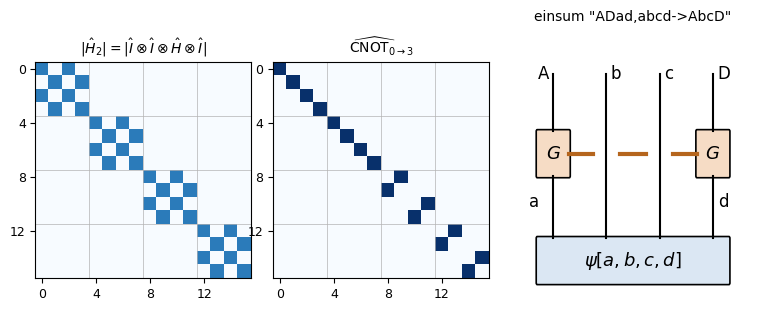

In [20]:
P0, P1 = jnp.diag(jnp.array([1, 0], dtype=CDTYPE)), jnp.diag(jnp.array([0, 1], dtype=CDTYPE))

def cnot_kron(i, j, N):
    # |0><0|_i (x) I_rest + |1><1|_i (x) X_j (x) I_rest, each term a Kronecker product over all N qubits
    t0 = reduce(jnp.kron, [P0 if k == i else I2 for k in range(N)])
    t1 = reduce(jnp.kron, [P1 if k == i else (X if k == j else I2) for k in range(N)])
    return t0 + t1

def apply_2q_einsum(psi, G, i, j, N):
    # contract the (2,2,2,2) gate tensor G[b_i', b_j', b_i, b_j] with axes i and j of the state tensor
    L = "abcdefghij"[:N]
    out = L.replace(L[i], L[i].upper()).replace(L[j], L[j].upper())
    spec = f"{L[i].upper()}{L[j].upper()}{L[i]}{L[j]},{L}->{out}"
    return jnp.einsum(spec, G.reshape(2, 2, 2, 2), psi.reshape((2,) * N)).reshape(-1), spec

def cnot_permutation(psi, i, j, N):
    # flip bit j of the index wherever bit i is 1
    idx = np.arange(2 ** N)
    perm = np.where((idx >> (N - 1 - i)) & 1, idx ^ (1 << (N - 1 - j)), idx)
    return psi[perm], perm

for (i, j) in [(0, 3), (3, 0), (1, 2), (2, 0)]:
    ref = cnot_kron(i, j, N4) @ psi4
    via_einsum, spec = apply_2q_einsum(psi4, CNOT, i, j, N4)        # CNOT: first factor = control
    via_perm, perm = cnot_permutation(psi4, i, j, N4)
    assert jnp.allclose(ref, via_einsum, atol=TOL) and jnp.allclose(ref, via_perm, atol=TOL)
    if (i, j) in [(0, 3), (3, 0)]:
        moved = [(format(k, "04b"), format(int(perm[k]), "04b")) for k in range(16) if perm[k] > k]
        print(f"CNOT_{i}->{j}: einsum '{spec}', exchanged bit strings {moved}")
for G in (R2("z", 0.7), CZ):                                          # any 4x4 gate on the pair (1, 3)
    # Kronecker reference: expand G in two-qubit Pauli strings a (x) b and place a on qubit 1, b on qubit 3
    ref = sum(jnp.trace(jnp.kron(PAULI1[a], PAULI1[b]).conj().T @ G) / 4 *
              reduce(jnp.kron, [I2, PAULI1[a], I2, PAULI1[b]]) for a in "IXYZ" for b in "IXYZ") @ psi4
    assert jnp.allclose(ref, apply_2q_einsum(psi4, G, 1, 3, N4)[0], atol=1e-10)
print("CNOT on non-neighbouring pairs: kron, einsum and permutation agree; R_zz and CZ on (1, 3) agree with the Kronecker form")

# GHZ_4 from H_0 and a chain or a fan-out of CNOTs
ghz4 = (basis_vector([0] * 4) + basis_vector([1] * 4)) / jnp.sqrt(2.0)
start = op_on_qubit(H, 0, N4) @ basis_vector([0] * 4)
chain, fan = start, start
for (i, j) in [(0, 1), (1, 2), (2, 3)]:
    chain = cnot_kron(i, j, N4) @ chain
for (i, j) in [(0, 1), (0, 2), (0, 3)]:
    fan = apply_2q_einsum(fan, CNOT, i, j, N4)[0]
assert jnp.allclose(chain, ghz4, atol=TOL) and jnp.allclose(fan, ghz4, atol=TOL)
print("GHZ_4 from H_0 and the CNOT chain, and from H_0 and the CNOT fan-out")

def cnot_sparse(i, j, N):
    # |0><0|_i (x) I + |1><1|_i (x) X_j as a sum of two sparse Kronecker products
    return op_on_qubits({i: P0}, N) + op_on_qubits({i: P1, j: X}, N)
for (i, j) in [(0, 3), (3, 0), (1, 2)]:
    C_sp = cnot_sparse(i, j, N4)
    assert np.allclose(C_sp.toarray(), np.asarray(cnot_kron(i, j, N4))) and C_sp.nnz == 2 ** N4    # a permutation: one 1 per row
    assert np.allclose(C_sp @ np.asarray(psi4), np.asarray(cnot_permutation(psi4, i, j, N4)[0]))
print("sparse CNOT_{i->j}: nnz = 2^N, equal to the dense Kronecker form and to the permutation")

fig = plt.figure(figsize=(7.2, 3.0))
ax1 = fig.add_axes([0.0, 0.08, 0.3, 0.8]); ax2 = fig.add_axes([0.33, 0.08, 0.3, 0.8]); ax3 = fig.add_axes([0.66, 0.0, 0.34, 0.95])
for ax, M_, title in ((ax1, H_2, r"$|\hat H_2|=|\hat I\otimes\hat I\otimes\hat H\otimes\hat I|$"), (ax2, cnot_kron(0, 3, N4), r"$\widehat{\mathrm{CNOT}}_{0\to3}$")):
    ax.imshow(np.abs(np.asarray(M_)), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 4, 8, 12]); ax.set_yticks([0, 4, 8, 12]); ax.tick_params(labelsize=9)
    for g in (3.5, 7.5, 11.5):
        ax.axhline(g, color="0.7", lw=0.5); ax.axvline(g, color="0.7", lw=0.5)
    ax.set_title(title, fontsize=10)
ax3.set_xlim(-0.3, 4.3); ax3.set_ylim(-0.2, 3.0); ax3.axis("off"); ax3.set_title("einsum \"ADad,abcd->AbcD\"", fontsize=10)
tn_box(ax3, 2.0, 0.4, 3.6, 0.5, r"$\psi[a,b,c,d]$")
for x in (0.5, 3.5):
    tn_leg(ax3, x, 0.65, x, 1.35)
tn_box(ax3, 0.5, 1.6, 0.6, 0.5, r"$G$", "#f6dcc5"); tn_box(ax3, 3.5, 1.6, 0.6, 0.5, r"$G$", "#f6dcc5")
ax3.plot([0.8, 1.25], [1.6, 1.6], color="#b5651d", lw=3); ax3.plot([1.75, 2.25], [1.6, 1.6], color="#b5651d", lw=3)
ax3.plot([2.75, 3.2], [1.6, 1.6], color="#b5651d", lw=3)
for x, lab in ((1.5, "b"), (2.5, "c")):
    tn_leg(ax3, x, 0.65, x, 2.5, lab)
tn_leg(ax3, 0.5, 1.85, 0.5, 2.5, "A", "left"); tn_leg(ax3, 3.5, 1.85, 3.5, 2.5, "D")
ax3.text(0.05, 1.0, "a", fontsize=12); ax3.text(3.6, 1.0, "d", fontsize=12)
save(fig, "fig_lab065_kron_structure"); plt.show()


The left panel shows the moduli of the 256 entries of $\hat H_2$. The matrix is block diagonal with four copies of $\hat H\otimes \hat I$, separated by grey lines. Inside each block the entries $1/\sqrt2$ sit two places apart, at the partner indices $i$ and $i\oplus2$. The middle panel shows $\widehat{\mathrm{CNOT}}_{0\to3}$. Its upper half, where $b_0=0$, is the identity, and its lower half exchanges neighbouring indices, the bit strings that differ in $b_3$. The right panel is the diagram of a gate on qubits 0 and 3, one tensor with four legs drawn as two boxes joined by a thick line. The legs of qubits 1 and 2 pass through untouched. The contraction touches only the two legs of the gate, so its cost grows as $2^N$ while the matrix grows as $4^N$.

## 12. Entanglement

### 12.1 A Bell state

Two qubits are entangled when their joint state cannot be written as a product of single-qubit states. The Bell state
$$|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2} \tag{23}$$
gives a random bit on each qubit alone, with probability one half for each outcome, while the two bits measured along $z$ always agree. Its entanglement lies in these joint predictions. Starting in $|00\rangle$, the Hadamard gate on qubit 0 gives $(|00\rangle+|10\rangle)/\sqrt2$, and CNOT flips qubit 1 in the second branch, so $\widehat{\mathrm{CNOT}}\,(\hat H\otimes \hat I)\,|00\rangle=|\Phi^+\rangle$. The interaction $\hat R_{xx}(\pi/2)$ acting on $|00\rangle$ gives $(|00\rangle-i|11\rangle)/\sqrt2$, which the phase gate $\hat S$ on qubit 0 maps to $|\Phi^+\rangle$. The two preparations differ by a gate on one qubit.

### 12.2 The product test and the Schmidt decomposition

A state is a product state when it can be written as $|\psi^{(0)}\rangle\otimes|\psi^{(1)}\rangle$. Its amplitudes are then $\psi[b_0,b_1]=\psi^{(0)}_{b_0}\psi^{(1)}_{b_1}$. The $2\times2$ amplitude matrix $\Psi[b_0,b_1]=\psi[b_0,b_1]$, the state tensor read as a matrix with qubit 0 labelling rows, is therefore an outer product of rank one. For $|0\rangle\otimes|+\rangle$,
$$\Psi=\frac1{\sqrt2}\begin{pmatrix}1&1\\0&0\end{pmatrix}=1\cdot\begin{pmatrix}1\\0\end{pmatrix}\begin{pmatrix}1/\sqrt2&1/\sqrt2\end{pmatrix}, \tag{24}$$
of rank one, whereas $|\Phi^+\rangle$ has $\Psi=I/\sqrt2$ of rank two, so the Bell state cannot be a product. A state whose matrix has rank two is entangled.

The singular value decomposition (SVD) writes every complex matrix as
$$\Psi=U\Sigma V^\dagger,\qquad \Sigma=\mathrm{diag}(s_1,s_2),\qquad s_1\ge s_2\ge0, \tag{25}$$
with two unitary $2\times2$ matrices $U$ and $V$ and the non-negative singular values $s_k$. In components it reads $\Psi_{b_0b_1}=\sum_kU_{b_0k}\,s_k\,(V^\dagger)_{kb_1}$, and read back as a state it is the Schmidt decomposition
$$|\psi\rangle=\sum_ks_k\,|u_k\rangle\otimes|v_k^*\rangle,\qquad s_1^2+s_2^2=1, \tag{26}$$
a sum of at most two product terms. The Schmidt vectors $|u_k\rangle$ of qubit 0 are the columns of $U$, with the components $U_{b_0k}$. The Schmidt vectors $|v_k^*\rangle$ of qubit 1 are the rows of $V^\dagger$, with the components $(V^\dagger)_{kb_1}=V^*_{b_1k}$, the complex conjugates of the columns of $V$. NumPy and JAX return $U$, the singular values and $V^\dagger$, so `u[:, k]` and `vt[k, :]` are the two Schmidt vectors of the $k$-th term. The code checks this on a product state with complex amplitudes, where the conjugation matters.

The $|u_k\rangle$ are orthonormal, and so are the $|v_k^*\rangle$, so a measurement of qubit 0 in the basis $\{|u_k\rangle\}$ finds the $k$-th term with probability $s_k^2$. The Schmidt coefficients $s_k$ therefore set the uncertainty of each qubit alone and measure entanglement. The number of nonzero coefficients is the Schmidt rank, one for a product state ($s_2=0$) and two for an entangled state of two qubits. For $|0\rangle\otimes|+\rangle$ equation (24) gives $s_1=1$ and $s_2=0$, with $|u_1\rangle=|0\rangle$ and $|v_1^*\rangle=|+\rangle$. For $|\Phi^+\rangle$ the coefficients are $s_1=s_2=1/\sqrt2$, the largest possible spread.

A gate on qubit 0 alone, with the $2\times2$ matrix $A$, turns the amplitude matrix into $A\Psi$, and a gate on qubit 1 alone, with the matrix $B$, into $\Psi B^T$. Multiplication by a unitary matrix from either side leaves the singular values unchanged, so a single-qubit gate leaves the Schmidt coefficients unchanged and can neither create nor remove entanglement. It can still change individual correlators, as $\hat X$ on qubit 1 turns $\langle \hat Z_0\hat Z_1\rangle=1$ of $|\Phi^+\rangle$ into $-1$. The two preparations of Section 12.1 therefore make equally entangled states.

Predict the Schmidt coefficients of $|0\rangle|+\rangle$ and of the Bell state from the rank of their amplitude matrices before running the code, which prints them.

In [21]:
bell = CNOT @ apply_1q(jnp.kron(ket0, ket0), H, 0)
assert jnp.allclose(bell, (basis_vector([0, 0]) + basis_vector([1, 1])) / jnp.sqrt(2.0), atol=TOL)
assert jnp.allclose(apply_1q(half, S, 0), bell, atol=TOL)          # S on qubit 0 maps R_xx(pi/2)|00> to the Bell state

def schmidt(psi):
    u, s, vt = jnp.linalg.svd(psi.reshape(2, 2))
    return u, s, vt          # psi = sum_k s_k u[:, k] (x) vt[k, :]

for name, state in [("|0>|+>", prod), ("tilted product", psi_prod), ("Bell", bell), ("random", psi_r)]:
    u, s, vt = schmidt(state)
    assert jnp.allclose(u.conj().T @ u, I2, atol=TOL) and jnp.allclose(vt @ vt.conj().T, I2, atol=TOL)
    rebuilt = sum(s[k] * jnp.kron(u[:, k], vt[k, :]) for k in range(2))
    assert jnp.allclose(rebuilt, state, atol=TOL)
    rank = int(jnp.sum(s > 1e-10))
    print(f"{name:15s} Schmidt coefficients {np.round(np.asarray(s), 4)}  rank {rank}  ->", "product" if rank == 1 else "entangled")
# numpy/jax return vt = V^dagger; the Schmidt vector of qubit 1 is the row vt[k, :], a conjugated column of V
phi_c = jnp.array([1, 2j], dtype=CDTYPE) / jnp.sqrt(5.0); chi_c = jnp.array([1, jnp.exp(0.8j)], dtype=CDTYPE) / jnp.sqrt(2.0)
u_c, s_c, vt_c = schmidt(jnp.kron(phi_c, chi_c))
assert abs(s_c[0] - 1) < 1e-10 and abs(s_c[1]) < 1e-10
assert abs(abs(jnp.vdot(chi_c, vt_c[0])) - 1) < 1e-10           # the row of vt is chi itself, up to a phase
assert abs(abs(jnp.vdot(chi_c, vt_c[0].conj())) - 1) > 1e-3     # its conjugate is a different state
print("complex product state: Schmidt vector of qubit 1 = row vt[0] (equal to chi up to a phase)")
u, s_prod, vt = schmidt(prod)
assert jnp.allclose(jnp.abs(u[:, 0]), jnp.abs(ket0), atol=TOL) and jnp.allclose(jnp.abs(vt[0]), jnp.abs(plus), atol=TOL)
# a gate on one qubit changes Psi into A Psi or Psi B^T and leaves the Schmidt coefficients unchanged
for U in (H, S, rotation([0.2, -1.0, 0.4], 1.1)):
    assert jnp.allclose(schmidt(apply_1q(psi_r, U, 0))[1], schmidt(psi_r)[1], atol=1e-10)
    assert jnp.allclose(schmidt(apply_1q(psi_r, U, 1))[1], schmidt(psi_r)[1], atol=1e-10)
assert abs(expect(apply_1q(bell, X, 1), jnp.kron(Z, Z)) + 1) < TOL   # but X on qubit 1 flips <Z0 Z1> of the Bell state
s_bell = schmidt(bell)[1]
assert jnp.allclose(s_bell, jnp.array([1, 1]) / jnp.sqrt(2.0), atol=TOL)
NUMBERS["SchmidtBell"] = f"{float(s_bell[0]):.4f}"
print("orthonormal u_k, v_k checked; the two Schmidt terms rebuild every state; single-qubit gates leave the Schmidt coefficients unchanged")

|0>|+>          Schmidt coefficients [1. 0.]  rank 1  -> product
tilted product  Schmidt coefficients [1. 0.]  rank 1  -> product
Bell            Schmidt coefficients [0.7071 0.7071]  rank 2  -> entangled
random          Schmidt coefficients [0.9082 0.4185]  rank 2  -> entangled
complex product state: Schmidt vector of qubit 1 = row vt[0] (equal to chi up to a phase)
orthonormal u_k, v_k checked; the two Schmidt terms rebuild every state; single-qubit gates leave the Schmidt coefficients unchanged


The family $\cos\theta\,|00\rangle+\sin\theta\,|11\rangle$ interpolates between a product state at $\theta=0$ and the Bell state at $\theta=\pi/4$. Its matrix is $\mathrm{diag}(\cos\theta,\sin\theta)$, so the Schmidt coefficients are $|\cos\theta|$ and $|\sin\theta|$. Their squares $s_k^2$ are probabilities, and they equal the eigenvalues of the state of one qubit alone, from which the entanglement entropy is computed.

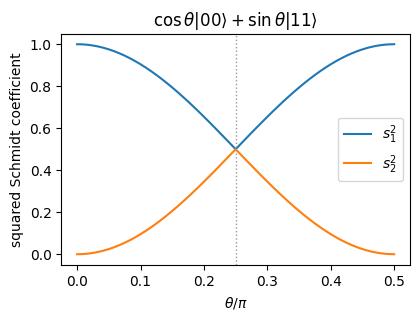

In [22]:
thetas = np.linspace(0, np.pi / 2, 61)
ss = np.array([np.asarray(schmidt(jnp.cos(t) * basis_vector([0, 0]) + jnp.sin(t) * basis_vector([1, 1]))[1]) for t in thetas])
assert np.allclose(ss, np.sort(np.abs(np.c_[np.cos(thetas), np.sin(thetas)]), axis=1)[:, ::-1], atol=1e-10)
fig, ax = plt.subplots()
ax.plot(thetas / np.pi, ss[:, 0] ** 2, label=r"$s_1^2$")
ax.plot(thetas / np.pi, ss[:, 1] ** 2, label=r"$s_2^2$")
ax.axvline(0.25, color="0.6", ls=":", lw=1)
ax.set_xlabel(r"$\theta/\pi$"); ax.set_ylabel("squared Schmidt coefficient")
ax.set_title(r"$\cos\theta|00\rangle+\sin\theta|11\rangle$"); ax.legend()
save(fig, "fig_lab065_schmidt"); plt.show()

The two squared Schmidt coefficients start at $1$ and $0$ for the product state. They meet at $1/2$ at $\theta=\pi/4$ (dotted line), where the state is the Bell state. Beyond $\pi/4$ the two terms exchange their roles, and the state returns to the product $|11\rangle$ at $\theta=\pi/2$.

### 12.3 Bell correlations in three bases

We sample $|\Phi^+\rangle$ in the settings $\hat Z\hat Z$, $\hat X\hat X$ and $\hat Y\hat Y$. The state is an eigenstate of $\hat Z\otimes \hat Z$ and $\hat X\otimes \hat X$ with eigenvalue $+1$ and of $\hat Y\otimes \hat Y$ with eigenvalue $-1$. Each qubit alone therefore gives random bits in every basis, while the two bits always agree in $\hat Z\hat Z$ and $\hat X\hat X$ and always disagree in $\hat Y\hat Y$.

A classical correlated coin, which prepares $|00\rangle$ or $|11\rangle$ with probability one half each, matches the $\hat Z\hat Z$ record. In each run it holds a definite product state along $z$, which gives independent random bits in the $\hat X$ and $\hat Y$ bases. Its correlators $\langle \hat X\hat X\rangle$ and $\langle \hat Y\hat Y\rangle$ therefore vanish. We simulate both preparations with the same number of shots and separate random keys.

ZZ: Bell <..> = +1.000 +- 0.000 (exact +1), coin <..> = +1.000 +- 0.000, fraction of bit 1 on qubit 0 = 0.510
XX: Bell <..> = +1.000 +- 0.000 (exact +1), coin <..> = -0.006 +- 0.016, fraction of bit 1 on qubit 0 = 0.497
YY: Bell <..> = -1.000 +- 0.000 (exact -1), coin <..> = -0.002 +- 0.016, fraction of bit 1 on qubit 0 = 0.487


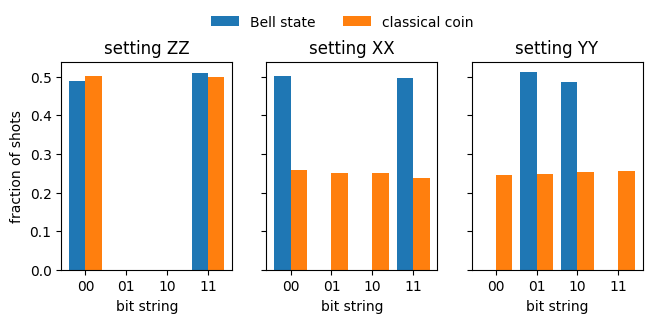

In [23]:
SHOTS_BELL = 4000
results = {}
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.7), sharey=True)
labels = ["00", "01", "10", "11"]; xs = np.arange(4)
for ax, setting in zip(axes, ("ZZ", "XX", "YY")):
    key, k_bell, k_which, k_00, k_11 = jax.random.split(key, 5)
    b0, b1 = measure_in_setting(k_bell, bell, setting, SHOTS_BELL)
    m_q, e_q = estimate((-1.0) ** (b0 + b1))
    # classical coin: each run holds |00> or |11> with probability 1/2 and is measured in the same setting
    which = np.asarray(jax.random.bernoulli(k_which, 0.5, (SHOTS_BELL,)))
    c00 = measure_in_setting(k_00, basis_vector([0, 0]), setting, SHOTS_BELL)
    c11 = measure_in_setting(k_11, basis_vector([1, 1]), setting, SHOTS_BELL)
    cb0 = np.where(which, c11[0], c00[0]); cb1 = np.where(which, c11[1], c00[1])
    m_c, e_c = estimate((-1.0) ** (cb0 + cb1))
    exact = float(expect(bell, jnp.kron(PAULIS[setting[0]], PAULIS[setting[1]])).real)
    results[setting] = dict(exact=exact, bell=m_q, bell_se=e_q, coin=m_c, coin_se=e_c,
                            marginal0=float(np.mean(b0)), counts_bell=counts(b0, b1), counts_coin=counts(cb0, cb1))
    assert abs(m_q - exact) < 5 * e_q + 1e-12
    ax.bar(xs - 0.2, [results[setting]["counts_bell"][l] / SHOTS_BELL for l in labels], 0.4, label="Bell state")
    ax.bar(xs + 0.2, [results[setting]["counts_coin"][l] / SHOTS_BELL for l in labels], 0.4, label="classical coin")
    ax.set_xticks(xs, labels); ax.set_title(f"setting {setting}"); ax.set_xlabel("bit string")
    print(f"{setting}: Bell <..> = {m_q:+.3f} +- {e_q:.3f} (exact {exact:+.0f}), coin <..> = {m_c:+.3f} +- {e_c:.3f}, "
          f"fraction of bit 1 on qubit 0 = {np.mean(b0):.3f}")
axes[0].set_ylabel("fraction of shots")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=2, fontsize=10, frameon=False)
save(fig, "fig_lab065_bell_records"); plt.show()
assert abs(results["XX"]["coin"]) < 5 * results["XX"]["coin_se"] and abs(results["YY"]["coin"]) < 5 * results["YY"]["coin_se"]
for s_ in ("ZZ", "XX", "YY"):
    NUMBERS[f"Bell{s_}"] = f"{results[s_]['bell']:+.3f}"; NUMBERS[f"Coin{s_}"] = f"{results[s_]['coin']:+.3f}"
    NUMBERS[f"BellSE{s_}"] = f"{results[s_]['bell_se']:.3f}"; NUMBERS[f"CoinSE{s_}"] = f"{results[s_]['coin_se']:.3f}"
NUMBERS["BellShots"] = f"{SHOTS_BELL}" 

For the Bell state (blue) only two of the four bit strings occur in each panel. In $\hat Z\hat Z$ and $\hat X\hat X$ they are $00$ and $11$, so the bits agree in every shot. In $\hat Y\hat Y$ they are $01$ and $10$, and the bits always disagree. The fraction of the bit 1 on qubit 0 is close to one half in every setting, so each qubit alone looks like a fair coin. The classical correlated coin (orange) matches the Bell state in $\hat Z\hat Z$. In $\hat X\hat X$ and $\hat Y\hat Y$ it produces all four bit strings with equal frequency, and its correlators are zero within their standard errors. No mixture of $|00\rangle$ and $|11\rangle$ gives all three records.

### 12.4 Single-qubit Bloch vectors during an entangling rotation

For one qubit the three expectation values $(\langle \hat X\rangle,\langle \hat Y\rangle,\langle \hat Z\rangle)$ form the Bloch vector, of length one for every pure state. For a qubit of the register we compute the same three numbers with the operators $\hat X\otimes \hat I$, $\hat Y\otimes \hat I$ and $\hat Z\otimes \hat I$. We write the angle of the entangling rotation as $\theta_{xx}$, to keep it apart from the angle $\theta$ of the family $\cos\theta|00\rangle+\sin\theta|11\rangle$. During the rotation
$$\hat R_{xx}(\theta_{xx})|00\rangle=\cos\tfrac{\theta_{xx}}2|00\rangle-i\sin\tfrac{\theta_{xx}}2|11\rangle \tag{27}$$
the Bloch vector of qubit 0 is $(0,0,\cos\theta_{xx})$. It shrinks to zero at $\theta_{xx}=\pi/2$, where the register is maximally entangled, and grows again, pointing down, towards $|11\rangle$ at $\theta_{xx}=\pi$. Its length equals $s_1^2-s_2^2$, the difference of the squared Schmidt coefficients. A vector inside the sphere belongs to no pure state, so the qubit alone needs the density matrix for its description.

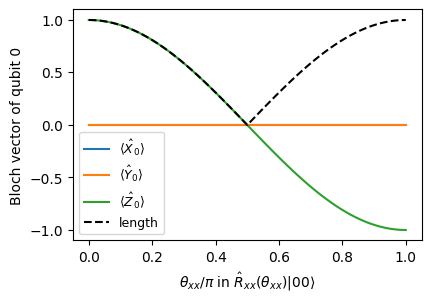

In [24]:
ths = np.linspace(0, np.pi, 91)
bloch = []
for t in ths:
    st = R2("x", t) @ basis_vector([0, 0])
    bloch.append([float(expect(st, jnp.kron(P, I2)).real) for P in (X, Y, Z)])
bloch = np.array(bloch)
assert np.allclose(bloch[:, 2], np.cos(ths), atol=1e-10) and np.allclose(bloch[:, :2], 0, atol=1e-10)
sk = np.array([np.asarray(schmidt(R2("x", t) @ basis_vector([0, 0]))[1]) for t in ths])
assert np.allclose(np.linalg.norm(bloch, axis=1), sk[:, 0] ** 2 - sk[:, 1] ** 2, atol=1e-10)   # length = s1^2 - s2^2
fig, ax = plt.subplots()
for k, lab in enumerate((r"$\langle\hat X_0\rangle$", r"$\langle\hat Y_0\rangle$", r"$\langle\hat Z_0\rangle$")):
    ax.plot(ths / np.pi, bloch[:, k], label=lab)
ax.plot(ths / np.pi, np.linalg.norm(bloch, axis=1), "k--", label="length")
ax.set_xlabel(r"$\theta_{xx}/\pi$ in $\hat R_{xx}(\theta_{xx})|00\rangle$"); ax.set_ylabel("Bloch vector of qubit 0")
ax.legend(fontsize=9)
save(fig, "fig_lab065_bloch_shrink"); plt.show()
NUMBERS["BlochLengthBell"] = f"{np.linalg.norm(bloch[45]):.3f}" 

The dashed curve shows the length of the Bloch vector of qubit 0, $|\cos\theta_{xx}|$. It is one only at $\theta_{xx}=0$ and $\theta_{xx}=\pi$, where the register is in the product states $|00\rangle$ and $|11\rangle$, and zero at $\theta_{xx}=\pi/2$. The $x$ and $y$ components stay zero throughout.

## 13. The register's Hamiltonian

Physical qubits interact through a Hamiltonian. A common model couples two spins by the Heisenberg exchange of Section 9.1 and adds a uniform field term along $z$, of strength $h$ in units of energy,
$$\hat{\mathcal H}=J\,(\hat X_0\hat X_1+\hat Y_0\hat Y_1+\hat Z_0\hat Z_1)+h\,(\hat Z_0+\hat Z_1),\qquad \hat X_0\hat X_1\equiv \hat X\otimes \hat X,\ \hat Z_0\equiv \hat Z\otimes \hat I. \tag{28}$$
Each term is a Pauli string multiplied by a real coefficient, and the Hamiltonian is a $4\times4$ Hermitian matrix built from these Kronecker products. Its eigenvalues are the energy levels, and its eigenvectors are the stationary states, whose measurement probabilities do not change in time. The eigenvector with the lowest energy is the ground state, the state a cold system settles into. Exact diagonalisation computes all of them.

The exchange term has the eigenvalue $J$ on the three symmetric states and $-3J$ on the singlet. The field term counts the spins, since $\hat Z_0+\hat Z_1$ is $+2$ on $|00\rangle$, $-2$ on $|11\rangle$ and $0$ on the states with one $1$. The four energies are therefore $J+2h$ for $|00\rangle$, $J-2h$ for $|11\rangle$, $J$ for $(|01\rangle+|10\rangle)/\sqrt2$ and $-3J$ for the singlet. For $J>0$ the coupling is antiferromagnetic, so antiparallel spins have the lower exchange energy. The singlet, an entangled state with $s_1=s_2=1/\sqrt2$, is then the ground state at weak field. A positive field lowers the energy of spins in $|1\rangle$. For $h>2J$ the level of $|11\rangle$ falls below the singlet and $|11\rangle$ becomes the ground state, and for $h<-2J$ the ground state is $|00\rangle$.

energies at h = 0: [-3.  1.  1.  1.]
ground state: [ 0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j] | Schmidt coefficients [0.7071 0.7071]
the register Hamiltonian built as a sparse matrix equals the dense Kronecker form


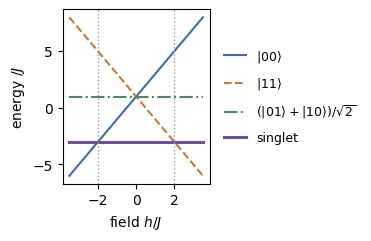

In [25]:
def heisenberg_register(J, h):
    XX, YY, ZZ = jnp.kron(X, X), jnp.kron(Y, Y), jnp.kron(Z, Z)
    return J * (XX + YY + ZZ) + h * (jnp.kron(Z, I2) + jnp.kron(I2, Z))

J = 1.0
Hreg = heisenberg_register(J, 0.0)
assert jnp.allclose(Hreg, Hreg.conj().T, atol=TOL)
E, V = jnp.linalg.eigh(Hreg)
gs = V[:, 0]
print("energies at h = 0:", np.round(np.asarray(E), 6))
print("ground state:", np.round(np.asarray(gs), 4), "| Schmidt coefficients", np.round(np.asarray(schmidt(gs)[1]), 4))
assert jnp.isclose(E[0], -3 * J) and jnp.isclose(abs(jnp.vdot(singlet, gs)), 1)

hs = np.linspace(-3.5, 3.5, 141)
levels = np.array([np.asarray(jnp.linalg.eigvalsh(heisenberg_register(J, h))) for h in hs])
pred = np.c_[J + 2 * hs, J - 2 * hs, J + 0 * hs, -3 * J + 0 * hs]
assert np.allclose(np.sort(pred, axis=1), levels, atol=1e-10)
fig, ax = plt.subplots(figsize=(3.6, 2.3), layout="constrained")     # final size: 0.55 of a 6.6 in text width
level_styles = [dict(color="#3b6ea8"), dict(color="#c8783a", ls="--"), dict(color="#4a8a5a", ls="-."), dict(color="#6d4f9c", lw=2.2)]
for k, lab in enumerate((r"$|00\rangle$", r"$|11\rangle$", r"$(|01\rangle+|10\rangle)/\sqrt{2}$", "singlet")):
    ax.plot(hs, pred[:, k], label=lab, **level_styles[k])
ax.axvline(2 * J, color="0.6", ls=":", lw=1); ax.axvline(-2 * J, color="0.6", ls=":", lw=1)
ax.set_xlabel(r"field $h/J$"); ax.set_ylabel(r"energy $/J$"); ax.set_xticks([-2, 0, 2])
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, handlelength=1.8, labelspacing=0.9)
save(fig, "fig_lab065_levels", tight=False); plt.show()
gs_strong = jnp.linalg.eigh(heisenberg_register(J, 2.5))[1][:, 0]
assert jnp.isclose(abs(gs_strong[3]), 1)         # |11> for h = 2.5 J
NUMBERS["GroundEnergy"] = f"{float(E[0]):.0f}" 
def heisenberg_sparse(N, J, h, pairs):
    # J sum over pairs (X_i X_j + Y_i Y_j + Z_i Z_j) + h sum_q Z_q, built from sparse Kronecker products
    Hs = sp.csr_matrix((2 ** N, 2 ** N), dtype=complex)
    for (i, j) in pairs:
        for P in (X, Y, Z):
            Hs = Hs + J * op_on_qubits({i: P, j: P}, N)
    for q in range(N):
        Hs = Hs + h * op_on_qubits({q: Z}, N)
    return Hs.tocsr()
for h_ in (0.0, 0.7, 2.5):
    assert np.allclose(heisenberg_sparse(2, J, h_, [(0, 1)]).toarray(), np.asarray(heisenberg_register(J, h_)))
print("the register Hamiltonian built as a sparse matrix equals the dense Kronecker form")


The four lines are the energies against the field. The singlet line is flat at $-3J$, because $(\hat Z_0+\hat Z_1)$ gives zero on the singlet. The line of $|11\rangle$ falls with $h$ and crosses the singlet at $h=2J$, the right dotted line, and the line of $|00\rangle$ crosses it at $h=-2J$. Between the two crossings the ground state is entangled, and outside them it is a product state. A parameter of the Hamiltonian switches the ground state between an entangled and a product state, the smallest example of a ground-state problem that variational quantum circuits address.

## 14. An excitation hopping between the spins

A gate is the evolution under a Hamiltonian for a fixed time, and following the state continuously in time shows how entanglement builds up. We take the exchange coupling without the $\hat Z\hat Z$ part,
$$\hat{\mathcal H}_{XX}=\frac J2\,(\hat X_0\hat X_1+\hat Y_0\hat Y_1)=\frac J4\,\big(\hat\sigma_0^+\hat\sigma_1^-+\hat\sigma_0^-\hat\sigma_1^+\big)=J\,\big(|01\rangle\langle10|+|10\rangle\langle01|\big), \tag{29}$$
with the ladder operators $\hat\sigma^\pm=\hat X\pm i\hat Y$, for which $\hat\sigma_0^+\hat\sigma_1^-+\hat\sigma_0^-\hat\sigma_1^+=2(\hat X_0\hat X_1+\hat Y_0\hat Y_1)$. The hopping term moves one excitation from one spin to the other. Starting in $|01\rangle$, qubit 0 up and qubit 1 down, the state at time $t$ is
$$|\psi(t)\rangle=e^{-i\hat{\mathcal H}_{XX}t}|01\rangle=\cos(Jt)\,|01\rangle-i\sin(Jt)\,|10\rangle . \tag{30}$$
The spin expectation values oscillate as $\langle \hat Z_0(t)\rangle=\cos(2Jt)=-\langle \hat Z_1(t)\rangle$, and the Schmidt coefficients are $|\cos Jt|$ and $|\sin Jt|$. The excitation is shared equally, and the register is maximally entangled, at $Jt=\pi/4$. We compute the evolution from the eigendecomposition $e^{-i\hat{\mathcal H}t}=V\,e^{-iEt}V^\dagger$.

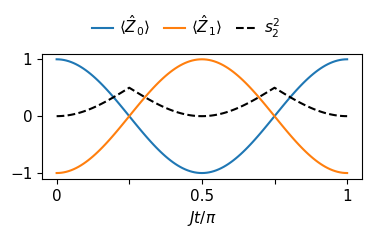

In [26]:
Hxx = J / 2 * (jnp.kron(X, X) + jnp.kron(Y, Y))
sp_, sm_ = X + 1j * Y, X - 1j * Y                    # sigma^+ = 2|0><1|, sigma^- = 2|1><0|
hop = jnp.kron(sp_, sm_) + jnp.kron(sm_, sp_)       # sigma_0^+ sigma_1^- + h.c.
assert jnp.allclose(hop, 2 * (jnp.kron(X, X) + jnp.kron(Y, Y)), atol=TOL) and jnp.allclose(Hxx, J / 4 * hop, atol=TOL)
assert jnp.allclose(Hxx, J * (jnp.outer(basis_vector([0, 1]), basis_vector([1, 0])) + jnp.outer(basis_vector([1, 0]), basis_vector([0, 1]))), atol=TOL)
Exx, Vxx = jnp.linalg.eigh(Hxx)
def evolve_register(psi0, t):
    return Vxx @ (jnp.exp(-1j * Exx * t) * (Vxx.conj().T @ psi0))

ts = np.linspace(0, np.pi, 121)
psi01 = basis_vector([0, 1])
traj = [evolve_register(psi01, t) for t in ts]
z0t = np.array([float(expect(p_, jnp.kron(Z, I2)).real) for p_ in traj])
z1t = np.array([float(expect(p_, jnp.kron(I2, Z)).real) for p_ in traj])
s2t = np.array([float(schmidt(p_)[1][1]) ** 2 for p_ in traj])
assert np.allclose(z0t, np.cos(2 * J * ts), atol=1e-10) and np.allclose(z1t, -np.cos(2 * J * ts), atol=1e-10)
assert jnp.allclose(evolve_register(psi01, 0.7), expm(-1j * Hxx * 0.7) @ psi01, atol=1e-10)
def plot_hopping(size, name):
    # drawn at its final printed size with 11 pt text, so the figure is placed without scaling
    rc = {"font.size": 11, "axes.labelsize": 11, "legend.fontsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11}
    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=size, layout="constrained")
        ax.plot(J * ts / np.pi, z0t, label=r"$\langle\hat Z_0\rangle$"); ax.plot(J * ts / np.pi, z1t, label=r"$\langle\hat Z_1\rangle$")
        ax.plot(J * ts / np.pi, s2t, "k--", label=r"$s_2^2$")
        ax.set_xlabel(r"$Jt/\pi$"); ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0", "", "0.5", "", "1"]); ax.set_yticks([-1, 0, 1])
        fig.legend(loc="outside upper center", ncol=3, frameon=False, handlelength=1.4, columnspacing=0.9, handletextpad=0.4)
        save(fig, name, tight=False)
    return fig

plot_hopping((2.5, 2.0), "fig_lab065_hopping_s")     # slide version
plt.close("all")
fig = plot_hopping((3.6, 2.3), "fig_lab065_hopping")  # lecture-notes version
plt.show()
NUMBERS["HoppingMaxSchmidt"] = f"{s2t.max():.3f}" 

The two magnetisations oscillate in opposite phase as the excitation moves back and forth. The smaller squared Schmidt coefficient, the dashed line, reaches the maximal entanglement $1/2$ whenever the magnetisations cross zero, at $Jt=\pi/4$ and $3\pi/4$. It returns to zero when the excitation sits on one spin. Records of $\langle \hat Z_0(t)\rangle$ and $\langle \hat Z_1(t)\rangle$ at many times are the data from which the unknown Hamiltonian of a device can be learned.

## 15. Energies from bit strings

Every term of $\hat{\mathcal H}$ is a Pauli string, and its expectation value can be read from measurement records through the parity of Section 11.1. Since the bit $0$ means the eigenvalue $+1$, a single shot of $\hat Z_0$ gives the value $(-1)^{b_0}$, and a shot of $\hat Z_0\hat Z_1$ gives the parity $(-1)^{b_0+b_1}$. The mean over $M$ shots estimates the expectation value with the standard error of Section 7. A Pauli string with $\hat X$ or $\hat Y$ factors is measured by first rotating each qubit with `BASIS_CHANGE` and then taking the same parity.

One setting measures several strings at once, as $\hat Z\hat Z$ gives $\hat Z_0$, $\hat Z_1$ and $\hat Z_0\hat Z_1$ from the same shots. In general one setting measures all Pauli strings that carry, on every qubit, either the identity or the Pauli matrix of the setting, and such strings commute with each other. The Hamiltonian (28) therefore needs three settings, $\hat X\hat X$ for $\hat X_0\hat X_1$, $\hat Y\hat Y$ for $\hat Y_0\hat Y_1$, and $\hat Z\hat Z$ for $\hat Z_0\hat Z_1$, $\hat Z_0$ and $\hat Z_1$. Each shot of a setting gives one value of the corresponding part of the energy. The parts are estimated independently, so their standard errors add in quadrature. We estimate the energy of the Bell state and of the product state $|0\rangle|+\rangle$ at $J=1$, $h=0.5$.

In [27]:
def energy_from_shots(key, psi, J, h, shots):
    parts, ses = [], []
    for setting in ("XX", "YY", "ZZ"):
        key, k = jax.random.split(key)
        b0, b1 = measure_in_setting(k, psi, setting, shots)
        z0, z1 = (-1.0) ** b0, (-1.0) ** b1          # eigenvalue of the measured Pauli on each qubit
        values = J * z0 * z1 + (h * (z0 + z1) if setting == "ZZ" else 0.0)
        m_, e_ = estimate(values); parts.append(m_); ses.append(e_)
    return sum(parts), float(np.sqrt(np.sum(np.square(ses))))

Jv, hv, SHOTS_E = 1.0, 0.5, 1000
NUMBERS["EnergyShots"] = f"{SHOTS_E}"
NUMBERS["EnergyField"] = f"{hv:.1f}"
energy_results = {}
for name, state in (("Bell", bell), ("product |0>|+>", psi_0plus)):
    key, k = jax.random.split(key)
    est, se = energy_from_shots(k, state, Jv, hv, SHOTS_E)
    exact = float(expect(state, heisenberg_register(Jv, hv)).real)
    energy_results[name] = dict(estimate=est, se=se, exact=exact)
    assert abs(est - exact) < 5 * se + 1e-12
    print(f"{name:16s}: energy from 3 x {SHOTS_E} shots = {est:+.3f} +- {se:.3f}, exact {exact:+.3f}")
NUMBERS["EnergyBellEst"] = f"{energy_results['Bell']['estimate']:+.3f}"
NUMBERS["EnergyBellExact"] = f"{energy_results['Bell']['exact']:+.3f}"
NUMBERS["EnergyProdEst"] = f"{energy_results['product |0>|+>']['estimate']:+.3f}"
NUMBERS["EnergyProdSE"] = f"{energy_results['product |0>|+>']['se']:.3f}"
NUMBERS["EnergyProdExact"] = f"{energy_results['product |0>|+>']['exact']:+.3f}" 

Bell            : energy from 3 x 1000 shots = +1.030 +- 0.032, exact +1.000
product |0>|+>  : energy from 3 x 1000 shots = +0.590 +- 0.065, exact +0.500


Both estimates agree with the exact energies within about 1.4 standard errors. The core route ends here.

## 16. Larger registers and a three-qubit gate

Beyond the core route, the same storage rule holds for any $N$. The GHZ state $(|0\dots0\rangle+|1\dots1\rangle)/\sqrt2$ has only two nonzero amplitudes, at index $0$ and at index $2^N-1$, but a state-vector simulation still allocates all $2^N$ of them. Its preparation extends the Bell circuit, $\hat H$ on qubit 0 followed by a chain or a fan-out of CNOT gates, as in Section 11.3.

Gates on three qubits follow the pattern of CNOT. The Toffoli gate flips qubit 2 when qubits 0 and 1 are both $1$, $|b_0b_1b_2\rangle\to|b_0,b_1,b_2\oplus(b_0\wedge b_1)\rangle$. With qubit 2 prepared in $|0\rangle$ it writes $b_0$ AND $b_1$ into qubit 2 and keeps the inputs, so it is a reversible AND gate. Together with NOT gates it builds every classical logic circuit reversibly. It is the evolution operator
$$\widehat{\mathrm{Toffoli}}=\exp\big[-i\pi(\hat I-\hat Z)\otimes(\hat I-\hat Z)\otimes(\hat I-\hat X)/8\big], \tag{31}$$
generated by the projector on $|1\rangle|1\rangle|-\rangle$, and it is stored as an $8\times8$ matrix in the same binary order. Its matrix is the identity except for the block that exchanges the amplitudes of $110$ and $111$, and its action on basis states is the truth table above. With the two-qubit gates of Section 9 it is compiled from six CNOT gates and single-qubit rotations.

## 17. Exercises

1. Write the eight basis vectors of three qubits as Kronecker products and check the position of $|110\rangle$ with equation (6).
2. Write the `einsum` string that applies a single-qubit gate to qubit 1 of a three-qubit state tensor, and check it against $\hat I\otimes \hat U\otimes \hat I$.
3. Prepare $|\Psi^-\rangle=(|01\rangle-|10\rangle)/\sqrt2$ with gates, predict its correlators in $\hat Z\hat Z$, $\hat X\hat X$ and $\hat Y\hat Y$, and then sample them.
4. Show that $\hat R_{yy}(\theta)$ acts on the pair $\{|00\rangle,|11\rangle\}$ as a rotation, and find its axis.
5. Compute the Schmidt coefficients of the state produced by $\hat R_{zz}(\theta)$ acting on $|{+}{+}\rangle$, and find the angle of maximal entanglement.
6. Show that a gate on qubit 1, with the matrix $B$, changes the amplitude matrix $\Psi$ into $\Psi B^T$, and conclude that it leaves the Schmidt coefficients unchanged.
7. Estimate the energy of the singlet from three settings, and explain why the estimate has no statistical error.

## 18. Summary

The state of $N$ qubits is a vector of $2^N$ complex amplitudes ordered by the Kronecker product, with qubit 0 as the most significant bit. Operators on the register are Kronecker products of single-qubit matrices. The same operations are contractions of the state tensor, which never build the $2^N\times2^N$ matrices, and sparse matrices store the Kronecker products of gates on $N$ qubits. Two-qubit gates are evolution operators of interactions, and entanglement requires such gates, since single-qubit gates leave the Schmidt coefficients unchanged. The Schmidt decomposition of the amplitude matrix tests a pure state for entanglement, and the Bell state gives correlations in three bases that no classical correlated coin produces. Energies of Pauli-string Hamiltonians follow from the parities of measured bit strings in a few settings.